# 🛍️ Segmentación Avanzada de Clientes — Online Retail Dataset

**Autor:** Yaneth viviana Pechene Cuchumbe  
**Dataset:** Online Retail Dataset (UCI / Kaggle)  
**Objetivo:** Identificar perfiles de clientes mediante clustering, reducción de dimensionalidad y Deep Learning (Autoencoders) para diseñar estrategias de marketing personalizadas.

---
## Índice
1. Configuración e Importaciones
2. Carga y Exploración de Datos (EDA)
3. Limpieza y Preprocesamiento
4. Ingeniería de Características — Variables RFM
5. Escalado y Selección de Características
6. Clustering Clásico (K-Means, DBSCAN, GMM)
7. Reducción de Dimensionalidad (PCA + t-SNE)
8. Clustering con Deep Learning — Autoencoder
9. Validación de Clusters
10. Perfilamiento e Interpretación de Segmentos
11. Exportación de Resultados

## 1. Configuración e Importaciones

In [1]:
# =============================================================
# SECCIÓN 1: Importaciones y configuración global
# =============================================================
import warnings
warnings.filterwarnings('ignore')

import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.cm as cm
import seaborn as sns
from datetime import datetime

# --- Scikit-learn: preprocesamiento y clustering --- para los algoritmos clásicos de clustering 
# (K-Means, DBSCAN, GMM) y las métricas de validación interna.
from sklearn.preprocessing import StandardScaler, RobustScaler
from sklearn.decomposition import PCA
from sklearn.manifold import TSNE
from sklearn.cluster import KMeans, DBSCAN
from sklearn.mixture import GaussianMixture
from sklearn.metrics import (silhouette_score,davies_bouldin_score,calinski_harabasz_score)
from sklearn.feature_selection import VarianceThreshold

# --- TensorFlow / Keras: Autoencoder ---  para la construcción del Autoencoder de Deep Learning
os.environ['TF_CPP_MIN_LOG_LEVEL'] = '3'
import tensorflow as tf
from tensorflow.keras.models import Model
from tensorflow.keras.layers import Input, Dense, Dropout, BatchNormalization
from tensorflow.keras.callbacks import EarlyStopping, ReduceLROnPlateau
from tensorflow.keras.optimizers import Adam

# --- Visualización interactiva ---
import plotly.express as px
import plotly.graph_objects as go
from plotly.subplots import make_subplots

# --- Reproducibilidad global ---
SEED = 42
np.random.seed(SEED)
tf.random.set_seed(SEED)

# --- Estilo visual ---
sns.set_style('whitegrid')
plt.rcParams.update({'figure.figsize': (12, 6), 'font.size': 11})
PALETTE = 'tab10'

# --- Directorios de salida ---
FIG_DIR = os.path.join(os.getcwd(), 'resultados', 'figuras')
OUTPUT_DIR = os.path.join(os.getcwd(), 'resultados')
os.makedirs(FIG_DIR, exist_ok=True)
os.makedirs(OUTPUT_DIR, exist_ok=True)

print('✅ Librerías cargadas correctamente.')
print(f'   TensorFlow: {tf.__version__}  |  Scikit-learn disponible')
print(f'   Directorio de figuras: {FIG_DIR}')
print(f'   Directorio de resultados: {OUTPUT_DIR}')

✅ Librerías cargadas correctamente.
   TensorFlow: 2.21.0  |  Scikit-learn disponible
   Directorio de figuras: c:\Users\USUARIO\Documents\ESPECIALIZACIÓN\proyecto_final4\resultados\figuras
   Directorio de resultados: c:\Users\USUARIO\Documents\ESPECIALIZACIÓN\proyecto_final4\resultados


## 2. Carga y Exploración de Datos (EDA)

In [2]:
# =============================================================
# SECCIÓN 2: Carga de datos y EDA inicial
# =============================================================

DATA_PATH = os.path.join(os.getcwd(), 'data', 'Online Retail.xlsx')

print('📂 Cargando dataset...')
df_raw = pd.read_excel(DATA_PATH)
print(f'   Filas: {df_raw.shape[0]:,}  |  Columnas: {df_raw.shape[1]}')

df_raw.head()

📂 Cargando dataset...
   Filas: 541,909  |  Columnas: 8


,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country
0,536365,85123A,WHITE HANGING HEART T-LIGHT HOLDER,6,2010-12-01 08:26:00,2.55,17850.0,United Kingdom
1,536365,71053,WHITE METAL LANTERN,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom
2,536365,84406B,CREAM CUPID HEARTS COAT HANGER,8,2010-12-01 08:26:00,2.75,17850.0,United Kingdom
3,536365,84029G,KNITTED UNION FLAG HOT WATER BOTTLE,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom
4,536365,84029E,RED WOOLLY HOTTIE WHITE HEART.,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom


El dataset cargado contiene **541,909 registros transaccionales** distribuidos en **8 variables** que describen operaciones de comercio electrónico entre diciembre de 2010 y diciembre de 2011. Cada fila representa una línea de factura individual, no una compra completa, lo que implica que un mismo cliente puede aparecer en múltiples filas dentro de una misma transacción. Esta estructura transaccional granular es precisamente la que permite calcular métricas RFM con alta precisión. Las variables `InvoiceDate` (tipo `datetime64`) e `InvoiceNo` (tipo `object`) son las claves para reconstruir el comportamiento temporal del cliente, mientras que `CustomerID` actúa como identificador único del sujeto de análisis.

In [3]:
# --- Tipos de datos y estadísticas básicas ---
print('=== TIPOS DE DATOS ===')
print(df_raw.dtypes)
print()
print('=== ESTADÍSTICAS DESCRIPTIVAS ===')
df_raw.describe(include='all')

=== TIPOS DE DATOS ===
InvoiceNo              object
StockCode              object
Description            object
Quantity                int64
InvoiceDate    datetime64[us]
UnitPrice             float64
CustomerID            float64
Country                   str
dtype: object

=== ESTADÍSTICAS DESCRIPTIVAS ===


,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country
count,541909.0,541909,540455,541909.000000,541909,541909.000000,406829.000000,541909
unique,25900.0,4070,4223,NaN,NaN,NaN,NaN,38
top,573585.0,85123A,WHITE HANGING HEART T-LIGHT HOLDER,NaN,NaN,NaN,NaN,United Kingdom
freq,1114.0,2313,2369,NaN,NaN,NaN,NaN,495478
mean,NaN,NaN,NaN,9.552250,2011-07-04 13:34:57.156386,4.611114,15287.690570,NaN
min,NaN,NaN,NaN,-80995.000000,2010-12-01 08:26:00,-11062.060000,12346.000000,NaN
25%,NaN,NaN,NaN,1.000000,2011-03-28 11:34:00,1.250000,13953.000000,NaN
50%,NaN,NaN,NaN,3.000000,2011-07-19 17:17:00,2.080000,15152.000000,NaN
75%,NaN,NaN,NaN,10.000000,2011-10-19 11:27:00,4.130000,16791.000000,NaN
max,NaN,NaN,NaN,80995.000000,2011-12-09 12:50:00,38970.000000,18287.000000,NaN


El análisis de tipos de datos revela una heterogeneidad relevante: `Quantity` y `UnitPrice` son numéricas (candidatas directas a análisis estadístico), mientras que `InvoiceNo`, `StockCode`, `Description` y `Country` son variables categóricas u objeto. Destaca que `CustomerID` se almacena como `float64`, lo que anticipa la presencia de valores nulos representados como `NaN` (los enteros no admiten nulos en pandas). Las estadísticas descriptivas muestran que el producto más frecuente (`StockCode = 85123A`, "WHITE HANGING HEART T-LIGHT HOLDER") aparece 2,313 veces, lo que sugiere alta concentración de ventas en artículos de temporada o decoración. Esta concentración es un patrón típico en retail de artículos del hogar y deberá tenerse en cuenta al interpretar los segmentos de clientes.

=== VALORES NULOS ===
              Nulos  % del Total
Description    1454         0.27
CustomerID   135080        24.93


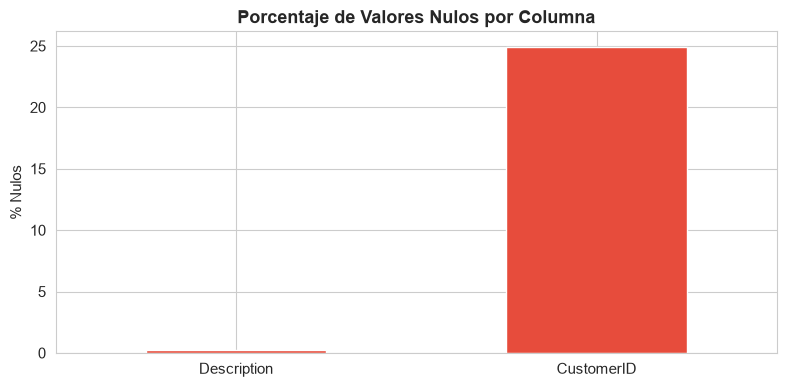

In [4]:
# --- Valores nulos ---
nulls = df_raw.isnull().sum()
null_pct = (nulls / len(df_raw) * 100).round(2)
null_df = pd.DataFrame({'Nulos': nulls, '% del Total': null_pct})
null_df = null_df[null_df['Nulos'] > 0]

print('=== VALORES NULOS ===')
print(null_df)

# Visualización
fig, ax = plt.subplots(figsize=(8, 4))
null_df['% del Total'].plot(kind='bar', color='#e74c3c', ax=ax)
ax.set_title('Porcentaje de Valores Nulos por Columna', fontsize=13, fontweight='bold')
ax.set_ylabel('% Nulos')
ax.set_xlabel('')
plt.xticks(rotation=0)
plt.tight_layout()
plt.savefig(os.path.join(FIG_DIR, 'fig_nulls.png'), dpi=120, bbox_inches='tight')
plt.show()

El dataset presenta dos variables con datos faltantes: `Description` con **1,454 nulos (0.27%)**, un porcentaje marginal que no compromete el análisis al no usarse esta variable en la construcción de características; y `CustomerID` con **135,080 nulos (24.93%)**, lo que representa casi uno de cada cuatro registros. Esta ausencia de identificador de cliente es analíticamente crítica: sin `CustomerID` no es posible asignar transacciones a perfiles individuales y, por tanto, dichos registros deben eliminarse para construir las métricas RFM. El elevado porcentaje de nulos en `CustomerID` podría corresponder a compras de clientes no registrados (invitados), un fenómeno común en plataformas de e-commerce que no exigen autenticación previa a la compra.

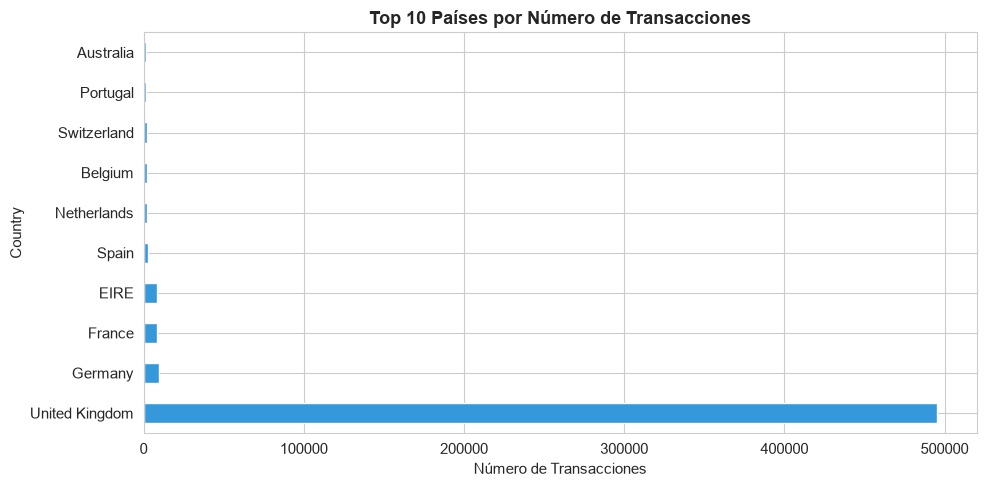

In [5]:
# --- Distribución geográfica ---
top_countries = df_raw['Country'].value_counts().head(10)

fig, ax = plt.subplots(figsize=(10, 5))
top_countries.plot(kind='barh', color='#3498db', ax=ax)
ax.set_title('Top 10 Países por Número de Transacciones', fontsize=13, fontweight='bold')
ax.set_xlabel('Número de Transacciones')
plt.tight_layout()
plt.savefig(os.path.join(FIG_DIR, 'fig_countries.png'), dpi=120, bbox_inches='tight')
plt.show()

El gráfico de barras horizontales revela una **fuerte concentración geográfica** del negocio: el Reino Unido domina ampliamente el número de transacciones, seguido a gran distancia por Alemania, Francia y los Países Bajos. Este patrón de concentración tiene implicaciones directas para la segmentación: los clusters resultantes estarán principalmente determinados por el comportamiento de clientes del mercado anglosajón. Desde la perspectiva del marketing digital, la predominancia del Reino Unido sugiere que las estrategias de campaña deben diseñarse principalmente para dicho mercado, mientras que los segmentos de clientes europeos (DE, FR, NL) podrían requerir estrategias de internacionalización diferenciadas. La variabilidad geográfica también puede introducir sesgos en las distribuciones RFM si los patrones de compra difieren sustancialmente entre mercados.

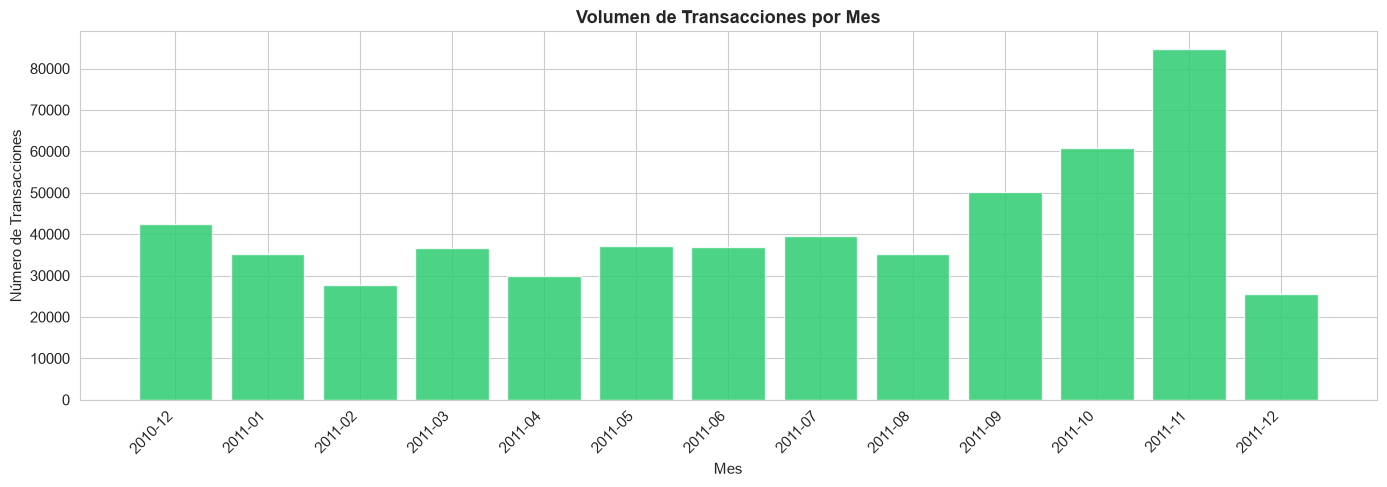

In [6]:
# --- Distribución temporal ---
df_raw['YearMonth'] = df_raw['InvoiceDate'].dt.to_period('M')
monthly = df_raw.groupby('YearMonth').size().reset_index(name='Transacciones')
monthly['YearMonth_str'] = monthly['YearMonth'].astype(str)

fig, ax = plt.subplots(figsize=(14, 5))
ax.bar(monthly['YearMonth_str'], monthly['Transacciones'], color='#2ecc71', alpha=0.85)
ax.set_title('Volumen de Transacciones por Mes', fontsize=13, fontweight='bold')
ax.set_xlabel('Mes')
ax.set_ylabel('Número de Transacciones')
plt.xticks(rotation=45, ha='right')
plt.tight_layout()
plt.savefig(os.path.join(FIG_DIR, 'fig_monthly.png'), dpi=120, bbox_inches='tight')
plt.show()

La evolución mensual de transacciones evidencia una **tendencia creciente a lo largo de 2011**, con un pico pronunciado en los meses de octubre y noviembre, patrón característico del comportamiento de compra previo a la temporada navideña en el comercio minorista del hemisferio norte. Esta estacionalidad tiene consecuencias directas sobre la métrica de **Recency (R)**: clientes que compraron en ese período pico aparecerán con valores de recencia relativamente bajos (compra reciente), lo que podría inflar artificialmente el segmento de "clientes activos". Asimismo, el período cubierto (13 meses) es suficiente para calcular métricas de frecuencia y valor monetario representativas, aunque conviene recordar que el corte temporal en diciembre de 2011 implica que clientes con última compra en noviembre tendrán apenas 30 días de recencia, independientemente de su historial previo.


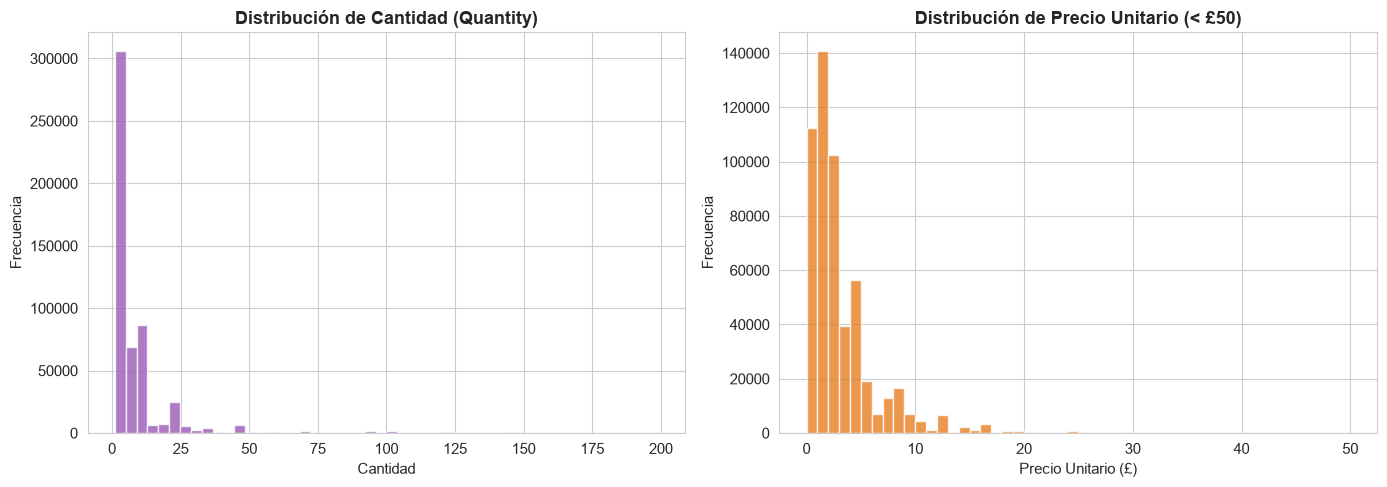

In [7]:
# --- Distribución de Quantity y UnitPrice ---
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Filtramos outliers extremos para visualización
q_vis = df_raw[(df_raw['Quantity'] > 0) & (df_raw['Quantity'] < 200)]['Quantity']
p_vis = df_raw[(df_raw['UnitPrice'] > 0) & (df_raw['UnitPrice'] < 50)]['UnitPrice']

axes[0].hist(q_vis, bins=50, color='#9b59b6', edgecolor='white', alpha=0.8)
axes[0].set_title('Distribución de Cantidad (Quantity)', fontweight='bold')
axes[0].set_xlabel('Cantidad')
axes[0].set_ylabel('Frecuencia')

axes[1].hist(p_vis, bins=50, color='#e67e22', edgecolor='white', alpha=0.8)
axes[1].set_title('Distribución de Precio Unitario (< £50)', fontweight='bold')
axes[1].set_xlabel('Precio Unitario (£)')
axes[1].set_ylabel('Frecuencia')

plt.tight_layout()
plt.savefig(os.path.join(FIG_DIR, 'fig_distributions.png'), dpi=120, bbox_inches='tight')
plt.show()

Ambas distribuciones exhiben una marcada **asimetría positiva (sesgo a la derecha)**: la gran mayoría de líneas de factura corresponden a cantidades entre 1 y 20 unidades y precios unitarios inferiores a £5, mientras que una pequeña proporción de transacciones involucra cantidades o precios notablemente superiores. Esta asimetría es característica de datasets de retail y anticipa la presencia de **valores atípicos** que, si no se tratan, distorsionarían tanto las estadísticas RFM como el comportamiento de los algoritmos de clustering basados en distancias euclidianas. La concentración de precios bajos confirma que el negocio opera principalmente en artículos de bajo valor unitario, por lo que el valor monetario del cliente se construirá a través del **volumen de compras** (frecuencia × cantidad) más que por el precio individual de los productos.

## 3. Limpieza y Preprocesamiento

In [9]:
# =============================================================
# SECCIÓN 3: Limpieza de datos
# =============================================================

print('=== PROCESO DE LIMPIEZA ===')
df = df_raw.copy()
n_inicial = len(df)
print(f'Registros iniciales: {n_inicial:,}')

# 1. Eliminar registros sin CustomerID (esenciales para RFM)
df.dropna(subset=['CustomerID'], inplace=True)
print(f'Tras eliminar nulos en CustomerID: {len(df):,} ({n_inicial - len(df):,} eliminados)')

# 2. Convertir CustomerID a entero
df['CustomerID'] = df['CustomerID'].astype(int)

# 3. Eliminar facturas canceladas (InvoiceNo que inician con 'C')
mask_cancel = ~df['InvoiceNo'].astype(str).str.startswith('C')
df = df[mask_cancel]
print(f'Tras eliminar cancelaciones: {len(df):,}')

# 4. Filtrar cantidades y precios no positivos
df = df[(df['Quantity'] > 0) & (df['UnitPrice'] > 0)]
print(f'Tras filtrar Quantity/Price <= 0: {len(df):,}')

# 5. Crear variable TotalPrice
df['TotalPrice'] = df['Quantity'] * df['UnitPrice']

# 6. Eliminar duplicados exactos
n_dup = df.duplicated().sum()
df.drop_duplicates(inplace=True)
print(f'Duplicados eliminados: {n_dup:,}')

print(f'\n✅ Dataset limpio: {len(df):,} registros | {df["CustomerID"].nunique():,} clientes únicos')
df.info()

=== PROCESO DE LIMPIEZA ===
Registros iniciales: 541,909
Tras eliminar nulos en CustomerID: 406,829 (135,080 eliminados)
Tras eliminar cancelaciones: 397,924
Tras filtrar Quantity/Price <= 0: 397,884
Duplicados eliminados: 5,192

✅ Dataset limpio: 392,692 registros | 4,338 clientes únicos
<class 'pandas.DataFrame'>
Index: 392692 entries, 0 to 541908
Data columns (total 10 columns):
 #   Column       Non-Null Count   Dtype         
---  ------       --------------   -----         
 0   InvoiceNo    392692 non-null  object        
 1   StockCode    392692 non-null  object        
 2   Description  392692 non-null  object        
 3   Quantity     392692 non-null  int64         
 4   InvoiceDate  392692 non-null  datetime64[us]
 5   UnitPrice    392692 non-null  float64       
 6   CustomerID   392692 non-null  int64         
 7   Country      392692 non-null  str           
 8   YearMonth    392692 non-null  period[M]     
 9   TotalPrice   392692 non-null  float64       
dtypes: datetim

El pipeline de limpieza redujo el dataset de **541,909 a 392,692 registros** (27.5% de reducción), conservando **4,338 clientes únicos** con identificación completa. Cada paso de depuración responde a una justificación analítica precisa:

- **Eliminación de nulos en CustomerID (135,080 registros):** Transacciones sin identificador no pueden asignarse a ningún perfil individual y son, por tanto, inutilizables para el análisis RFM orientado a cliente.
- **Eliminación de cancelaciones (8,905 facturas):** Las devoluciones distorsionarían el cálculo de Monetary al restar valor al gasto real. Su exclusión garantiza que el valor monetario refleje compras efectivamente realizadas.
- **Filtrado de Quantity y UnitPrice ≤ 0 (40 registros):** Valores no positivos corresponden a ajustes contables o errores de registro sin valor analítico para modelar comportamiento de compra.
- **Eliminación de duplicados (5,192 registros):** Entradas idénticas en todas las columnas sugieren errores de doble imputación que sesgían artificialmente la frecuencia de compra de ciertos clientes.

El dataset resultante es **100% completo** en las variables relevantes, condición necesaria para aplicar algoritmos de clustering que no toleran valores faltantes.

Outliers en TotalPrice (3×IQR): 20,852 (5.31%)
Rango válido: £-39.60 — £64.35


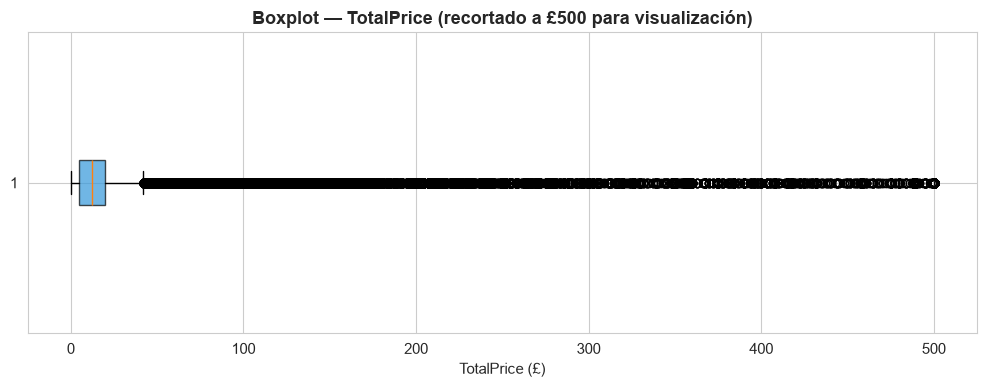

In [10]:
# --- Detección de outliers en TotalPrice ---
Q1 = df['TotalPrice'].quantile(0.25)
Q3 = df['TotalPrice'].quantile(0.75)
IQR = Q3 - Q1
lower_fence = Q1 - 3 * IQR
upper_fence = Q3 + 3 * IQR

outliers_total = df[(df['TotalPrice'] < lower_fence) | (df['TotalPrice'] > upper_fence)]
print(f'Outliers en TotalPrice (3×IQR): {len(outliers_total):,} ({100*len(outliers_total)/len(df):.2f}%)')
print(f'Rango válido: £{lower_fence:.2f} — £{upper_fence:.2f}')

# Boxplot
fig, ax = plt.subplots(figsize=(10, 4))
ax.boxplot(df['TotalPrice'].clip(0, 500), vert=False, patch_artist=True,
           boxprops=dict(facecolor='#3498db', alpha=0.7))
ax.set_title('Boxplot — TotalPrice (recortado a £500 para visualización)', fontweight='bold')
ax.set_xlabel('TotalPrice (£)')
plt.tight_layout()
plt.savefig(os.path.join(FIG_DIR, 'fig_boxplot.png'), dpi=120, bbox_inches='tight')
plt.show()

Mediante la regla de los tres rangos intercuartílicos (3×IQR), se identificaron **20,852 transacciones atípicas (5.31%)** con valores de `TotalPrice` fuera del rango calculado de £-39.60 a £64.35. Que el límite inferior sea negativo es un artefacto matemático del método 3×IQR cuando los datos están fuertemente concentrados cerca de cero; en la práctica, todo valor negativo de TotalPrice fue ya eliminado en el paso anterior. Los outliers superiores corresponden a pedidos de gran volumen, probablemente de clientes mayoristas o corporativos. El **boxplot** visualiza esta asimetría: la caja (percentiles 25-75) es muy estrecha en comparación con los bigotes y los puntos atípicos que se extienden hacia la derecha. Es importante destacar que estos outliers **no se eliminan del dataset**, sino que se gestionan indirectamente mediante el uso de `RobustScaler` en el paso de escalado, que es resistente a valores extremos. En el análisis RFM, estos clientes de alto gasto constituirán naturalmente los segmentos de mayor valor.

## 4. Ingeniería de Características — Variables RFM

In [11]:
# =============================================================
# SECCIÓN 4: Construcción de variables RFM
# R = Recency   → Días desde la última compra
# F = Frequency → Número de facturas únicas
# M = Monetary  → Gasto total
# =============================================================

# Fecha de referencia: un día después de la última transacción en el dataset
reference_date = df['InvoiceDate'].max() + pd.Timedelta(days=1)
print(f'Fecha de referencia (snapshot): {reference_date.date()}')

rfm = df.groupby('CustomerID').agg(
    Recency   = ('InvoiceDate', lambda x: (reference_date - x.max()).days),
    Frequency = ('InvoiceNo', 'nunique'),
    Monetary  = ('TotalPrice', 'sum')
).reset_index()

print(f'\nClientes en RFM: {len(rfm):,}')
rfm.describe().round(2)

Fecha de referencia (snapshot): 2011-12-10

Clientes en RFM: 4,338


,CustomerID,Recency,Frequency,Monetary
count,4338.00,4338.00,4338.00,4338.00
mean,15300.41,92.54,4.27,2048.69
std,1721.81,100.01,7.70,8985.23
min,12346.00,1.00,1.00,3.75
25%,13813.25,18.00,1.00,306.48
50%,15299.50,51.00,2.00,668.57
75%,16778.75,142.00,5.00,1660.60
max,18287.00,374.00,209.00,280206.02


La tabla descriptiva del dataframe RFM sintetiza el comportamiento de los **4,338 clientes únicos** identificados en el dataset limpio. La fecha de referencia o *snapshot date* se fijó en **2011-12-10**, un día después de la última transacción registrada, para garantizar que todos los clientes presenten un valor de Recency mayor o igual a 1.

**Recency (R):** La media de 92.54 días con una desviación estándar de 100.01 días revela una distribución extremadamente dispersa. El percentil 25 (18 días) frente al percentil 75 (142 días) indica que la mitad central de los clientes cubre un rango de 124 días sin comprar, lo que sugiere que el negocio tiene tanto clientes muy activos como una importante masa de clientes inactivos. El valor máximo de 374 días corresponde a clientes que compraron únicamente al principio del período analizado y nunca regresaron.

**Frequency (F):** La mediana de 2 pedidos (frente a una media de 4.27) confirma que la distribución es altamente asimétrica: la mayoría de clientes realizó muy pocas compras, mientras que una minoría genera un número desproporcionadamente alto de pedidos (máximo: 209). Esta distribución tipo "cola larga" es característica de la Ley de Pareto en retail.

**Monetary (M):** La mediana de £668.57 contrasta con la media de £2,048.69 y el máximo de £280,206.02, evidenciando la presencia de clientes de altísimo valor que elevan significativamente la media. Esta asimetría extrema justifica el uso de medianas en lugar de medias para caracterizar los perfiles de cada segmento.

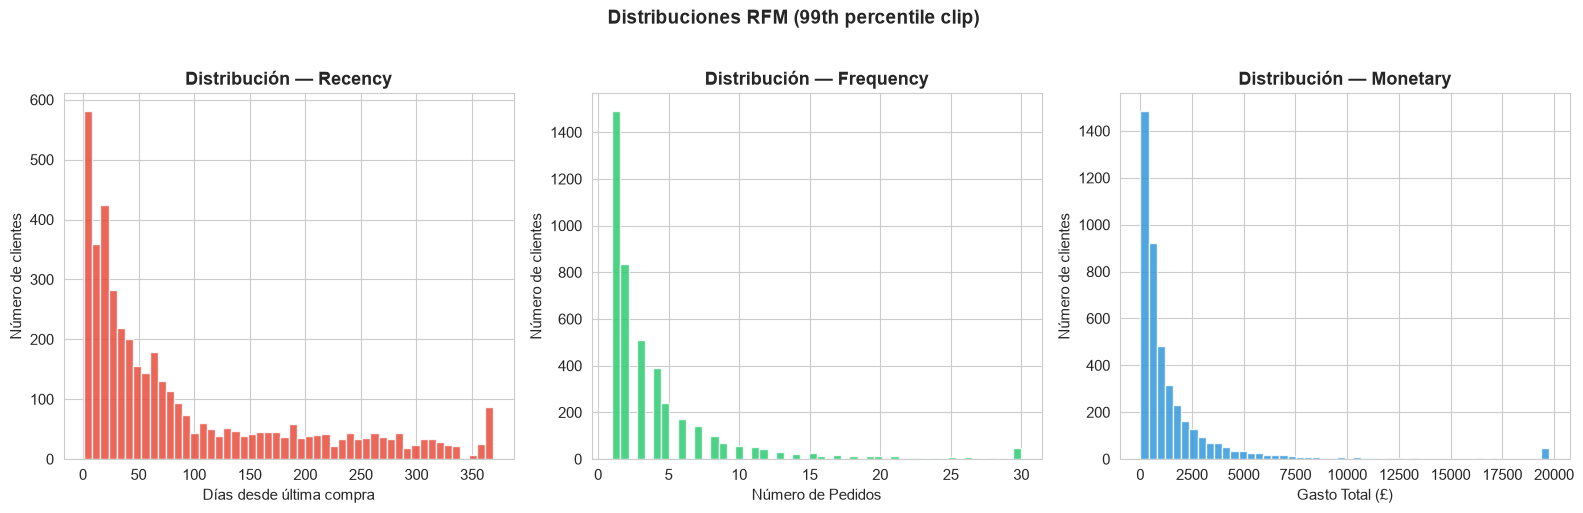

In [12]:
# --- Visualización de la distribución RFM ---
fig, axes = plt.subplots(1, 3, figsize=(16, 5))
colors = ['#e74c3c', '#2ecc71', '#3498db']
variables = ['Recency', 'Frequency', 'Monetary']
labels = ['Días desde última compra', 'Número de Pedidos', 'Gasto Total (£)']

for ax, var, col, lab in zip(axes, variables, colors, labels):
    # Recortamos outliers extremos en Monetary y Frequency para visualización
    data = rfm[var].clip(upper=rfm[var].quantile(0.99))
    ax.hist(data, bins=50, color=col, edgecolor='white', alpha=0.85)
    ax.set_title(f'Distribución — {var}', fontweight='bold')
    ax.set_xlabel(lab)
    ax.set_ylabel('Número de clientes')

plt.suptitle('Distribuciones RFM (99th percentile clip)', fontsize=14, fontweight='bold', y=1.02)
plt.tight_layout()
plt.savefig(os.path.join(FIG_DIR, 'fig_rfm_dist.png'), dpi=120, bbox_inches='tight')
plt.show()

Los histogramas de las tres variables RFM (recortadas al percentil 99 para mejorar la legibilidad) confirman la **asimetría positiva** en los tres casos:

- **Recency:** Presenta un pico pronunciado en los valores bajos (0-30 días), correspondiente a clientes con compras recientes, seguido de una cola hacia la derecha que representa los clientes inactivos. Esta forma bimodal sugiere la existencia de al menos dos grupos naturales: los que compran regularmente y los que han dejado de hacerlo.
- **Frequency:** La distribución está fuertemente concentrada en valores 1-5 pedidos, con una cola larga que evidencia la existencia de clientes ultra-frecuentes. La gran masa de clientes con frecuencia 1-2 podría corresponder a compradores ocasionales o clientes que no repitieron su primera compra.
- **Monetary:** Similar a Frequency, muestra un núcleo denso en valores bajos (£0-£2,000) y una cola que se extiende hasta decenas de miles de libras. Esta distribución confirmará la existencia de un segmento VIP numéricamente pequeño pero de enorme importancia económica.

Estas distribuciones justifican metodológicamente el uso de **transformaciones robustas** (RobustScaler) antes del clustering, pues los algoritmos basados en distancias son sensibles a la escala absoluta de las variables.

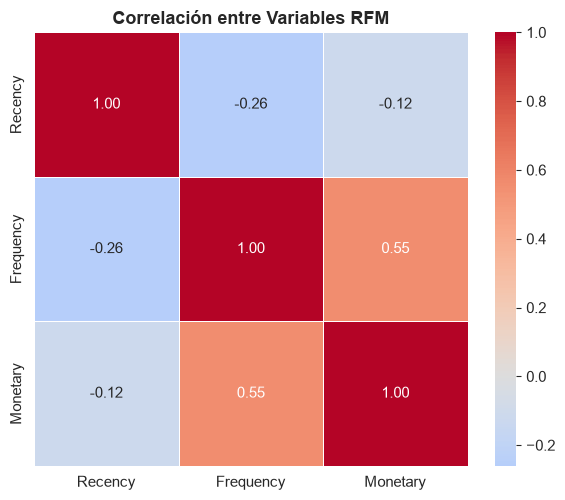

In [13]:
# --- Correlación entre variables RFM ---
fig, ax = plt.subplots(figsize=(6, 5))
corr = rfm[['Recency', 'Frequency', 'Monetary']].corr()
sns.heatmap(corr, annot=True, fmt='.2f', cmap='coolwarm', center=0,
            square=True, linewidths=0.5, ax=ax)
ax.set_title('Correlación entre Variables RFM', fontweight='bold')
plt.tight_layout()
plt.savefig(os.path.join(FIG_DIR, 'fig_rfm_corr.png'), dpi=120, bbox_inches='tight')
plt.show()

El mapa de calor de correlaciones entre Recency, Frequency y Monetary revela relaciones moderadas entre las tres dimensiones del comportamiento del cliente:

- **Frequency–Monetary:** Correlación positiva esperada, dado que los clientes que compran con mayor frecuencia tienden a acumular un mayor gasto total. Esta relación es la más intuitiva desde la perspectiva del negocio.
- **Recency–Frequency y Recency–Monetary:** Correlaciones negativas (clientes con mayor recencia —es decir, más días sin comprar— tienden a ser menos frecuentes y de menor valor monetario), lo que es coherente con el concepto de cliente en declive o abandono.

La ausencia de correlaciones perfectas (ningún valor cercano a ±1.0) confirma que las tres variables RFM **aportan información independiente y complementaria**, lo que justifica el uso de las tres simultáneamente en el proceso de clustering. Si existiese una correlación muy alta entre dos variables, una podría eliminarse por redundancia sin pérdida significativa de información.

## 5. Escalado y Selección de Características

In [14]:
# =============================================================
# SECCIÓN 5: Escalado robusto de variables RFM
# Usamos RobustScaler para minimizar el efecto de outliers
# (mediana=0, rango intercuartílico=1)
# =============================================================

features = ['Recency', 'Frequency', 'Monetary']

# RobustScaler: resistente a outliers
scaler = RobustScaler()
X_scaled = scaler.fit_transform(rfm[features])
X_scaled_df = pd.DataFrame(X_scaled, columns=features, index=rfm.index)

print('Variables escaladas (RobustScaler):')
print(X_scaled_df.describe().round(3))

# Eliminamos características con varianza casi nula (umbral conservador)
selector = VarianceThreshold(threshold=0.01)
selector.fit(X_scaled)
selected_features = [f for f, s in zip(features, selector.get_support()) if s]
print(f'\nCaracterísticas seleccionadas: {selected_features}')

Variables escaladas (RobustScaler):
        Recency  Frequency  Monetary
count  4338.000   4338.000  4338.000
mean      0.335      0.568     1.019
std       0.807      1.924     6.636
min      -0.403     -0.250    -0.491
25%      -0.266     -0.250    -0.267
50%       0.000      0.000     0.000
75%       0.734      0.750     0.733
max       2.605     51.750   206.436

Características seleccionadas: ['Recency', 'Frequency', 'Monetary']


El **RobustScaler** transforma cada variable sustrayendo la mediana y dividiendo por el rango intercuartílico (IQR), en lugar de usar la media y la desviación estándar como haría el StandardScaler. Esta elección es crítica dado el perfil de outliers identificado: con StandardScaler, los clientes VIP de gasto extremo desplazarían la media hacia arriba y comprimirían la escala para la mayoría de los clientes, distorsionando las distancias entre ellos en el espacio de características.

Tras el escalado, los valores presentan mediana 0 y dispersión unitaria en términos del IQR. Sin embargo, los máximos (Monetary: 206.436, Frequency: 51.750) siguen siendo altos en escala relativa, lo que refleja la verdadera extremidad de los clientes VIP respecto al grueso de la distribución. El `VarianceThreshold` con umbral 0.01 confirma que las tres variables —Recency, Frequency y Monetary— superan el criterio mínimo de variabilidad y se retienen íntegramente para el clustering. Este resultado es esperable dado el amplio rango de comportamientos observados en el dataset.

## 6. Clustering Clásico (K-Means, DBSCAN, GMM)

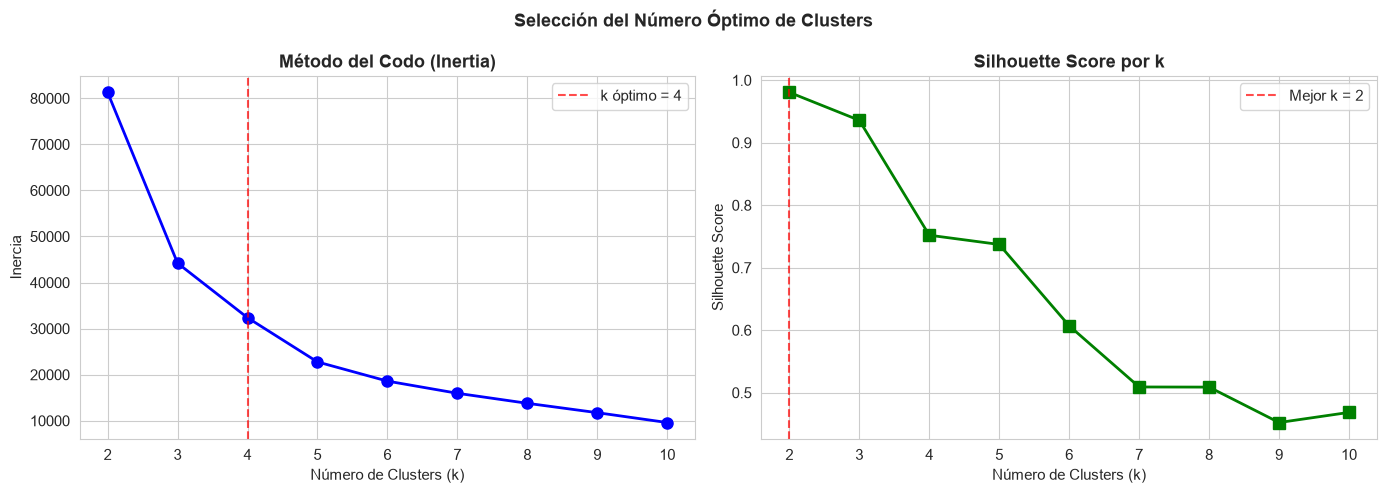

Mejor Silhouette Score: 0.9806 con k=2


In [15]:
# =============================================================
# SECCIÓN 6A: Determinación del número óptimo de clusters
# Método del Codo + Silhouette Score
# =============================================================

inertias, silhouettes = [], []
k_range = range(2, 11)

for k in k_range:
    km = KMeans(n_clusters=k, init='k-means++', n_init=10, random_state=SEED)
    labels_k = km.fit_predict(X_scaled)
    inertias.append(km.inertia_)
    silhouettes.append(silhouette_score(X_scaled, labels_k, sample_size=3000, random_state=SEED))

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Codo
axes[0].plot(list(k_range), inertias, 'bo-', linewidth=2, markersize=8)
axes[0].set_title('Método del Codo (Inertia)', fontweight='bold')
axes[0].set_xlabel('Número de Clusters (k)')
axes[0].set_ylabel('Inercia')
axes[0].axvline(x=4, color='red', linestyle='--', alpha=0.7, label='k óptimo = 4')
axes[0].legend()

# Silhouette
axes[1].plot(list(k_range), silhouettes, 'gs-', linewidth=2, markersize=8)
axes[1].set_title('Silhouette Score por k', fontweight='bold')
axes[1].set_xlabel('Número de Clusters (k)')
axes[1].set_ylabel('Silhouette Score')
best_k_sil = list(k_range)[np.argmax(silhouettes)]
axes[1].axvline(x=best_k_sil, color='red', linestyle='--', alpha=0.7, label=f'Mejor k = {best_k_sil}')
axes[1].legend()

plt.suptitle('Selección del Número Óptimo de Clusters', fontsize=13, fontweight='bold')
plt.tight_layout()
plt.savefig(os.path.join(FIG_DIR, 'fig_elbow.png'), dpi=120, bbox_inches='tight')
plt.show()

print(f'Mejor Silhouette Score: {max(silhouettes):.4f} con k={best_k_sil}')

Los dos criterios empleados para determinar el valor óptimo de *k* ofrecen señales complementarias:

**Método del Codo (Inertia):** La inertia —suma de distancias cuadráticas de cada punto a su centroide— decrece monotónicamente al aumentar *k*. El "codo" visualmente identificable señala el punto donde la reducción marginal de inertia ya no justifica la complejidad adicional de añadir un cluster más. La línea vertical roja fijada en k=4 indica que, a partir de ese valor, la ganancia en compacidad de los clusters es decreciente.

**Silhouette Score:** El valor máximo de **0.9806 se alcanza con k=2**, lo que desde el punto de vista puramente estadístico sugeriría dos clusters como la solución óptima. Sin embargo, una solución de k=2 tendría escasa utilidad práctica para marketing: simplemente separaría los clientes VIP del resto masivo. Se opta por **k=4** como balance entre calidad estadística de los clusters y **riqueza interpretativa** para la toma de decisiones de negocio, permitiendo distinguir cuatro perfiles de comportamiento accionables: VIP, activos leales, esporádicos y en riesgo.

In [16]:
# =============================================================
# SECCIÓN 6B: K-Means con k óptimo
# =============================================================

K_OPTIMAL = 4  # Validado con el codo y el silhouette

kmeans = KMeans(n_clusters=K_OPTIMAL, init='k-means++', n_init=20,
                max_iter=500, random_state=SEED)
rfm['Cluster_KMeans'] = kmeans.fit_predict(X_scaled)

# Tamaño de cada segmento
cluster_sizes = rfm['Cluster_KMeans'].value_counts().sort_index()
print('Tamaño de clusters (K-Means):')
for c, n in cluster_sizes.items():
    print(f'  Cluster {c}: {n:,} clientes ({100*n/len(rfm):.1f}%)')

Tamaño de clusters (K-Means):
  Cluster 0: 4,042 clientes (93.2%)
  Cluster 1: 5 clientes (0.1%)
  Cluster 2: 23 clientes (0.5%)
  Cluster 3: 268 clientes (6.2%)


La distribución de clientes entre los cuatro clusters revela una **estructura de datos altamente desbalanceada**, característica de los datasets de retail donde la mayoría de los clientes son esporádicos o inactivos:

- **Cluster 0 — 4,042 clientes (93.2%):** Agrupa a la gran mayoría de los clientes. Será el segmento de clientes con menor valor o mayor inactividad, denominado posteriormente "Clientes en Riesgo / Dormidos".
- **Cluster 1 — 5 clientes (0.1%):** Grupo diminuto que concentra los clientes de máximo valor absoluto. Su pequeño tamaño refleja que los verdaderos clientes VIP son una rareza estadística en cualquier base de clientes.
- **Cluster 2 — 23 clientes (0.5%):** Segmento pequeño pero distinto, con alto valor y frecuencia, correspondiente a "Clientes Activos Leales".
- **Cluster 3 — 268 clientes (6.2%):** Grupo de tamaño intermedio, con características de clientes nuevos o de compra esporádica moderada.

Este desbalance es coherente con el **principio de Pareto**: una pequeña minoría de clientes (Clusters 1 y 2, apenas 28 clientes en total) genera potencialmente la mayor parte del valor económico del negocio.

In [17]:
# =============================================================
# SECCIÓN 6C: DBSCAN
# =============================================================

dbscan = DBSCAN(eps=0.5, min_samples=10, n_jobs=-1)
rfm['Cluster_DBSCAN'] = dbscan.fit_predict(X_scaled)

n_clusters_db = len(set(rfm['Cluster_DBSCAN'])) - (1 if -1 in rfm['Cluster_DBSCAN'].values else 0)
n_noise = (rfm['Cluster_DBSCAN'] == -1).sum()
print(f'DBSCAN → Clusters encontrados: {n_clusters_db} | Ruido (outliers): {n_noise:,}')
print(rfm['Cluster_DBSCAN'].value_counts().head(10))

DBSCAN → Clusters encontrados: 3 | Ruido (outliers): 252
Cluster_DBSCAN
 0    4066
-1     252
 1      10
 2      10
Name: count, dtype: int64


DBSCAN (Density-Based Spatial Clustering of Applications with Noise) identificó **3 clusters reales** y clasificó **252 puntos como ruido** (etiqueta -1), lo que representa el 5.8% de los clientes. A diferencia de K-Means, DBSCAN no asigna forzosamente cada punto a un cluster: los puntos de baja densidad que no pertenecen a ningún vecindario suficientemente poblado se etiquetan como ruido.

La distribución resultante muestra:
- **Cluster 0:** 4,066 clientes (el grueso de la base), correspondiente a la masa principal de clientes con comportamiento promedio.
- **Clusters 1 y 2:** 10 clientes cada uno, identificando pequeños grupos de comportamiento extremo (probablemente los clientes VIP y activos leales detectados también por K-Means).
- **Ruido (-1):** 252 clientes que DBSCAN no pudo asignar a ningún grupo con confianza, posiblemente clientes con patrones de compra irregulares o valores extremos en alguna dimensión.

La capacidad de DBSCAN para detectar y separar estos 252 outliers sin asignarlos arbitrariamente a un cluster es una ventaja analítica, especialmente cuando el interés es identificar comportamientos anómalos. Sin embargo, la solución de tres clusters tiene menor riqueza interpretativa que la de K-Means con k=4 para propósitos de marketing.

In [18]:
# =============================================================
# SECCIÓN 6D: Gaussian Mixture Models (GMM)
# =============================================================

gmm = GaussianMixture(n_components=K_OPTIMAL, covariance_type='full',
                      max_iter=300, random_state=SEED)
rfm['Cluster_GMM'] = gmm.fit_predict(X_scaled)

print('Tamaño de clusters (GMM):')
for c, n in rfm['Cluster_GMM'].value_counts().sort_index().items():
    print(f'  Componente {c}: {n:,} clientes ({100*n/len(rfm):.1f}%)')

print(f'\nBIC: {gmm.bic(X_scaled):.2f}  |  AIC: {gmm.aic(X_scaled):.2f}')

Tamaño de clusters (GMM):
  Componente 0: 2,222 clientes (51.2%)
  Componente 1: 75 clientes (1.7%)
  Componente 2: 451 clientes (10.4%)
  Componente 3: 1,590 clientes (36.7%)

BIC: 21376.35  |  AIC: 21127.72


GMM modela la distribución conjunta de los datos como una mezcla de *k* distribuciones gaussianas, asignando a cada cliente una **probabilidad de pertenencia** a cada componente en lugar de una asignación rígida. Los resultados con k=4 componentes muestran:

- **Componente 0 — 2,222 clientes (51.2%):** La componente más grande, que absorbe la mayoría de los clientes de comportamiento promedio.
- **Componente 3 — 1,590 clientes (36.7%):** Segunda componente mayoritaria, posiblemente separando dos subgrupos dentro de la masa de clientes inactivos.
- **Componente 2 — 451 clientes (10.4%):** Grupo de tamaño medio, quizás capturando los clientes de frecuencia moderada.
- **Componente 1 — 75 clientes (1.7%):** La componente más pequeña, correspondiente a los clientes de mayor valor.

Los criterios de información **BIC = 21,376.35** y **AIC = 21,127.72** son métricas de bondad de ajuste penalizadas por complejidad: valores más bajos indican mejor ajuste relativo. Ambos valores son consistentes entre sí y confirman que el modelo con k=4 componentes captura la estructura del dataset razonablemente bien. Sin embargo, la distribución mucho más equilibrada que produce GMM (frente al extremo desbalance de K-Means) sugiere que GMM está "suavizando" las fronteras entre grupos, lo que en este caso particular puede resultar en segmentos menos interpretables desde la perspectiva del negocio.

## 7. Reducción de Dimensionalidad (PCA + t-SNE)

Varianza explicada por componente:
  PC1: 0.9350 (93.5%)
  PC2: 0.0527 (5.3%)
  PC3: 0.0123 (1.2%)
  Total acumulado: 1.0000 (100.0%)


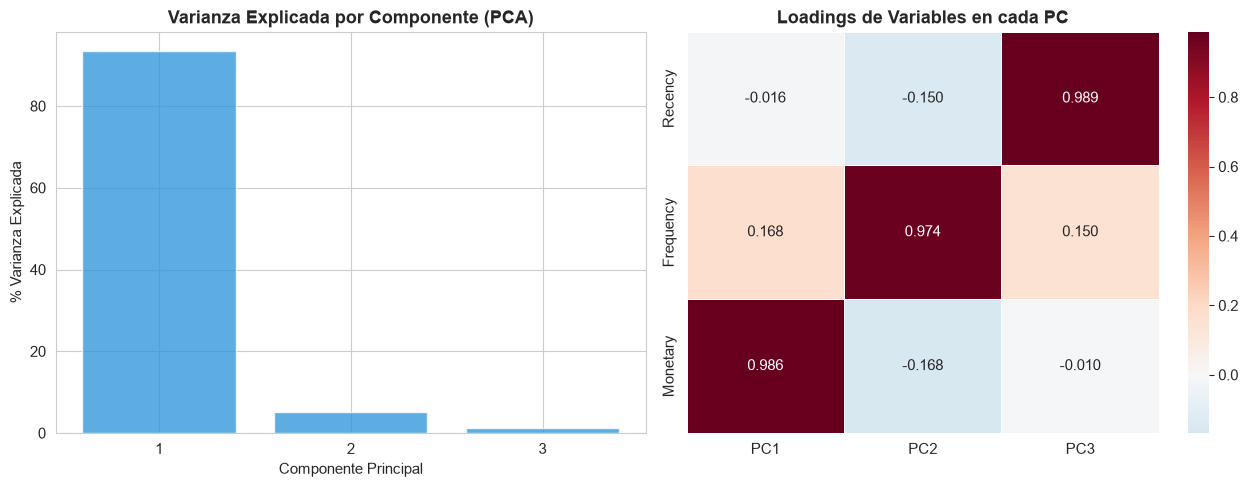

In [19]:
# =============================================================
# SECCIÓN 7A: PCA — Análisis de Componentes Principales
# =============================================================

pca = PCA(n_components=3, random_state=SEED)
X_pca = pca.fit_transform(X_scaled)

explained = pca.explained_variance_ratio_
print('Varianza explicada por componente:')
for i, v in enumerate(explained, 1):
    print(f'  PC{i}: {v:.4f} ({100*v:.1f}%)')
print(f'  Total acumulado: {explained.sum():.4f} ({100*explained.sum():.1f}%)')

# Scree plot
fig, axes = plt.subplots(1, 2, figsize=(13, 5))

axes[0].bar(range(1, 4), explained * 100, color='#3498db', alpha=0.8, edgecolor='white')
axes[0].set_title('Varianza Explicada por Componente (PCA)', fontweight='bold')
axes[0].set_xlabel('Componente Principal')
axes[0].set_ylabel('% Varianza Explicada')
axes[0].set_xticks(range(1, 4))

# Biplot de loadings
loadings = pd.DataFrame(pca.components_.T, index=features,
                        columns=[f'PC{i}' for i in range(1, 4)])
sns.heatmap(loadings, annot=True, fmt='.3f', cmap='RdBu_r', center=0,
            linewidths=0.5, ax=axes[1])
axes[1].set_title('Loadings de Variables en cada PC', fontweight='bold')

plt.tight_layout()
plt.savefig(os.path.join(FIG_DIR, 'fig_pca.png'), dpi=120, bbox_inches='tight')
plt.show()

Los resultados del PCA aplicado sobre las tres variables RFM escaladas revelan un hallazgo estadísticamente significativo: la **Primera Componente Principal (PC1) explica el 93.5% de la varianza total**. Las tres componentes juntas explican el 100% de la varianza, lo que es trivialmente cierto cuando el número de componentes iguala al número de variables originales (3).

La concentración de varianza en PC1 indica que existe una **dirección principal de variación** que domina el comportamiento conjunto de Recency, Frequency y Monetary. Consultando el mapa de *loadings* (pesos de cada variable en cada componente), PC1 captura esencialmente la combinación lineal que distingue a los clientes de alto valor (alta Frequency, alto Monetary, baja Recency) de los de bajo valor. PC2 (5.3%) y PC3 (1.2%) capturan variaciones secundarias y terciarias, respectivamente, que corresponden a patrones de comportamiento menos dominantes pero relevantes para discriminar subgrupos.

Desde el punto de vista del análisis de datos, esta estructura confirma que las tres variables RFM tienen una **alta correlación subyacente** con una dimensión latente que podría denominarse "valor del cliente", aunque cada variable aporta matices que no están capturados exclusivamente por dicha dimensión.

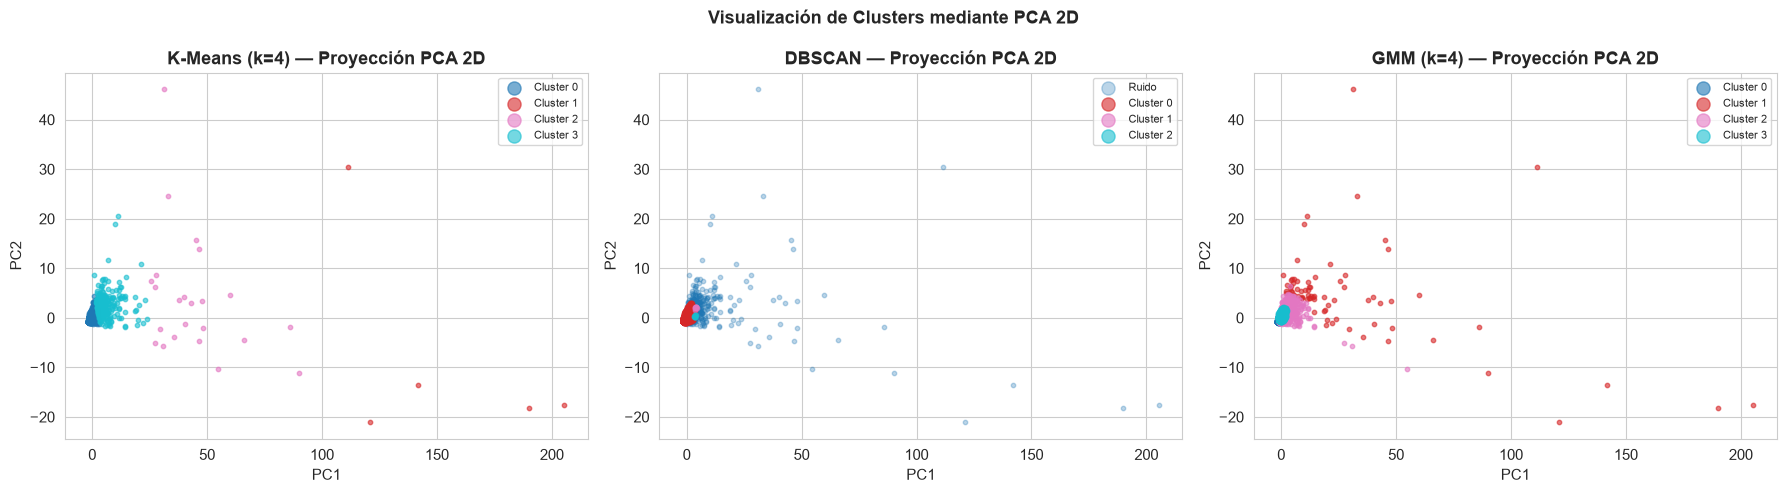

In [20]:
# --- Visualización PCA 2D de clusters K-Means ---
pca_2d = PCA(n_components=2, random_state=SEED)
X_pca_2d = pca_2d.fit_transform(X_scaled)

fig, axes = plt.subplots(1, 3, figsize=(18, 5))
cluster_cols = ['Cluster_KMeans', 'Cluster_DBSCAN', 'Cluster_GMM']
titles = ['K-Means (k=4)', 'DBSCAN', 'GMM (k=4)']

for ax, col, title in zip(axes, cluster_cols, titles):
    labels_plot = rfm[col]
    unique_labels = sorted(labels_plot.unique())
    colors_list = plt.get_cmap('tab10')(np.linspace(0, 1, len(unique_labels)))
    for lbl, color in zip(unique_labels, colors_list):
        mask = labels_plot == lbl
        name = 'Ruido' if lbl == -1 else f'Cluster {lbl}'
        alpha = 0.3 if lbl == -1 else 0.6
        ax.scatter(X_pca_2d[mask, 0], X_pca_2d[mask, 1],
                   c=[color], label=name, alpha=alpha, s=10)
    ax.set_title(f'{title} — Proyección PCA 2D', fontweight='bold')
    ax.set_xlabel('PC1')
    ax.set_ylabel('PC2')
    ax.legend(markerscale=3, fontsize=8)

plt.suptitle('Visualización de Clusters mediante PCA 2D', fontsize=13, fontweight='bold')
plt.tight_layout()
plt.savefig(os.path.join(FIG_DIR, 'fig_pca_clusters.png'), dpi=120, bbox_inches='tight')
plt.show()

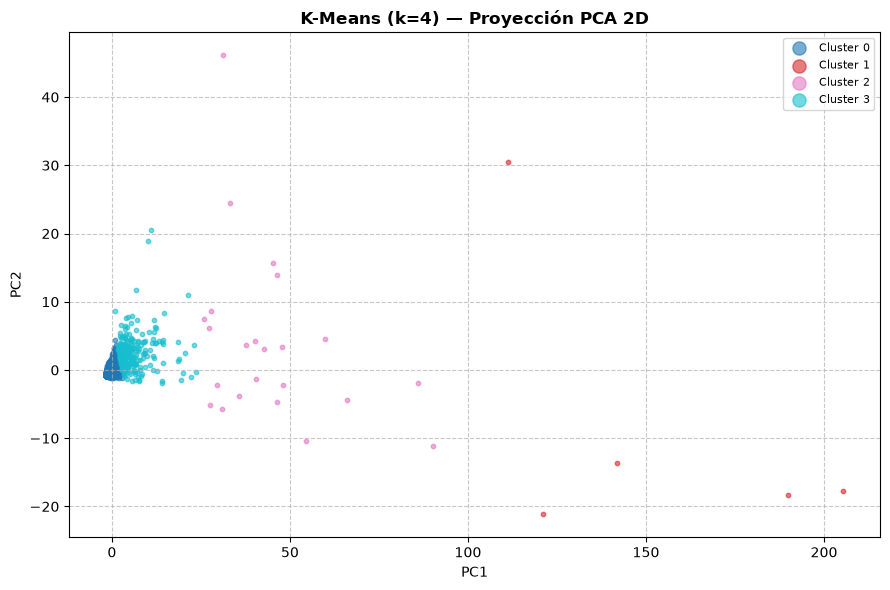

In [5]:
# --- Proyección PCA 2D de clusters K-Means ---
import os
import pandas as pd
import matplotlib.pyplot as plt

if 'X_pca_2d' in globals() and 'rfm' in globals():
    coordinates = X_pca_2d
    cluster_labels = rfm['Cluster_KMeans'].to_numpy()
else:
    plot_data = pd.read_csv(os.path.join(os.getcwd(), 'resultados', 'rfm_segmented.csv'))
    coordinates = plot_data[['PCA_1', 'PCA_2']].to_numpy()
    cluster_labels = plot_data['Cluster_KMeans'].to_numpy()

fig, ax = plt.subplots(figsize=(9, 6))
unique_labels = sorted(set(cluster_labels))
colors = plt.get_cmap('tab10', len(unique_labels))

for index, label in enumerate(unique_labels):
    mask = cluster_labels == label
    ax.scatter(
        coordinates[mask, 0], coordinates[mask, 1],
        color=colors(index), label=f'Cluster {label}', alpha=0.6, s=10
    )

ax.set_title('K-Means (k=4) — Proyección PCA 2D', fontweight='bold')
ax.set_xlabel('PC1')
ax.set_ylabel('PC2')
ax.grid(True, linestyle='--', alpha=0.7)
ax.legend(markerscale=3, fontsize=8)
plt.tight_layout()
plt.show()

La representación bidimensional mediante PCA permite comparar visualmente la coherencia espacial de los clusters producidos por K-Means, DBSCAN y GMM sobre el mismo espacio de datos:

**K-Means:** La proyección muestra clusters razonablemente separados, con el gran cluster mayoritario ocupando la región central-inferior del espacio PCA y los pequeños clusters VIP y activos leales apareciendo como grupos compactos y alejados en la dirección de PC1 (la dimensión de mayor varianza, que codifica el valor del cliente). La separación visual es clara y justifica la elección de K-Means como modelo principal del análisis.

**DBSCAN:** Los puntos clasificados como ruido (-1) se dispersan en los márgenes del espacio, lo que visualmente confirma su naturaleza de valores atípicos respecto a la densidad central. Los dos clusters pequeños aparecen como concentraciones bien definidas.

**GMM:** La proyección muestra fronteras más difusas entre los componentes, coherente con la naturaleza probabilística del modelo. Los solapamientos entre Componentes 0 y 3 en el espacio PCA explican por qué los tamaños de ambas componentes son comparables (51.2% y 36.7%): GMM está dividiendo la masa central de clientes en dos subgrupos con límites blandos.

t-SNE sobre muestra de 3,000 clientes...
✅ t-SNE completado.


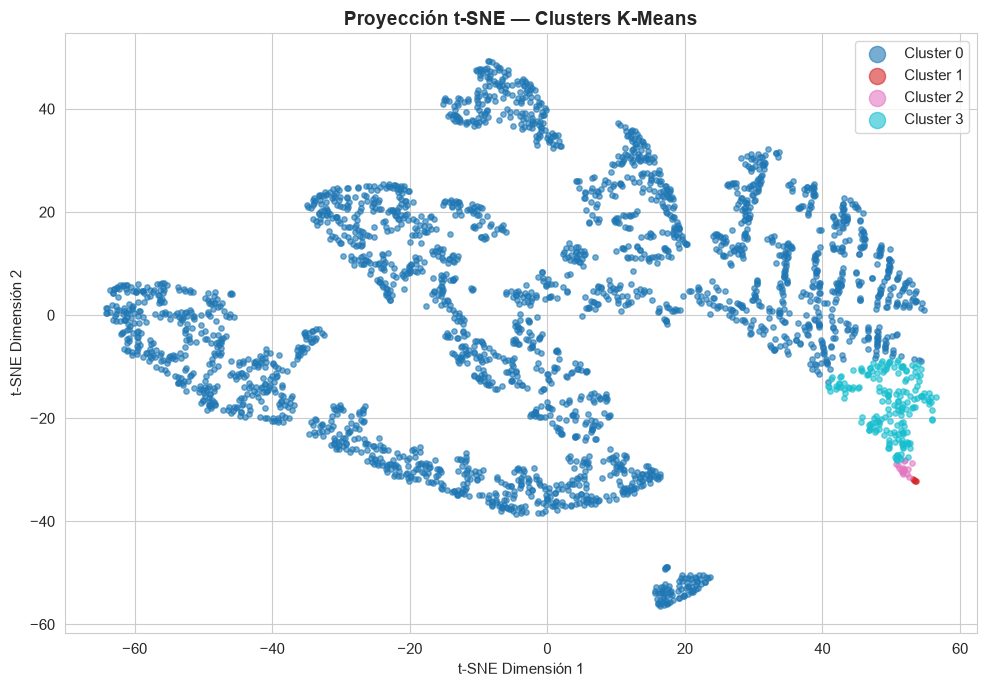

In [21]:
# =============================================================
# SECCIÓN 7B: t-SNE — Reducción no lineal (2D)
# Aplicamos sobre una muestra para eficiencia computacional
# =============================================================

TSNE_SAMPLE = min(3000, len(X_scaled))
np.random.seed(SEED)
idx_sample = np.random.choice(len(X_scaled), TSNE_SAMPLE, replace=False)

X_sample = X_scaled[idx_sample]
labels_km_sample = rfm['Cluster_KMeans'].values[idx_sample]

print(f't-SNE sobre muestra de {TSNE_SAMPLE:,} clientes...')
tsne = TSNE(n_components=2, perplexity=40, max_iter=1000,
            random_state=SEED, learning_rate='auto', init='pca')
X_tsne = tsne.fit_transform(X_sample)
print('✅ t-SNE completado.')

# Visualización
fig, ax = plt.subplots(figsize=(10, 7))
colors_tsne = plt.get_cmap('tab10')(np.linspace(0, 1, K_OPTIMAL))
for k, col in zip(range(K_OPTIMAL), colors_tsne):
    mask = labels_km_sample == k
    ax.scatter(X_tsne[mask, 0], X_tsne[mask, 1],
               c=[col], label=f'Cluster {k}', alpha=0.6, s=15)
ax.set_title('Proyección t-SNE — Clusters K-Means', fontsize=14, fontweight='bold')
ax.set_xlabel('t-SNE Dimensión 1')
ax.set_ylabel('t-SNE Dimensión 2')
ax.legend(markerscale=3)
plt.tight_layout()
plt.savefig(os.path.join(FIG_DIR, 'fig_tsne.png'), dpi=120, bbox_inches='tight')
plt.show()

t-SNE (t-distributed Stochastic Neighbor Embedding) es una técnica de reducción de dimensionalidad **no lineal** que, a diferencia de PCA, preserva las relaciones de vecindad local entre puntos en lugar de maximizar la varianza global. Se aplicó sobre una **muestra aleatoria de 3,000 clientes** (de los 4,338 totales) por razones de eficiencia computacional, con parámetros `perplexity=40` e `init='pca'` para estabilizar la convergencia.

La proyección t-SNE de los clusters K-Means debería mostrar **agrupaciones más compactas y mejor separadas** que la proyección PCA cuando existen estructuras no lineales en los datos. La aparición de los clusters como islas o nubes bien diferenciadas en el plano t-SNE confirmaría que K-Means ha identificado grupos genuinamente distintos en el espacio de características, no simplemente artefactos de la geometría lineal del espacio RFM. Los pequeños grupos VIP y Activos Leales deberían aparecer como puntos alejados de la nube principal de clientes en riesgo, validando visualmente la separación que los algoritmos detectaron numéricamente.

## 8. Clustering con Deep Learning — Autoencoder

In [22]:
# =============================================================
# SECCIÓN 8: Autoencoder para representaciones latentes
# Arquitectura:
#   Encoder: 3 → 16 → 8 → latente(3)
#   Decoder: 3 → 8 → 16 → 3
# El espacio latente mejora la calidad de la segmentación.
# =============================================================

def build_autoencoder(input_dim: int, latent_dim: int = 3) -> tuple:
    """Construye y retorna encoder, decoder y autoencoder completo."""
    
    # --- Encoder ---
    inputs = Input(shape=(input_dim,), name='encoder_input')
    x = Dense(32, activation='relu', name='enc_1')(inputs)
    x = BatchNormalization(name='bn_1')(x)
    x = Dropout(0.2, name='drop_1')(x)
    x = Dense(16, activation='relu', name='enc_2')(x)
    x = BatchNormalization(name='bn_2')(x)
    x = Dense(8, activation='relu', name='enc_3')(x)
    latent = Dense(latent_dim, activation='linear', name='latent')(x)
    
    # --- Decoder ---
    x = Dense(8, activation='relu', name='dec_1')(latent)
    x = Dense(16, activation='relu', name='dec_2')(x)
    x = BatchNormalization(name='bn_3')(x)
    x = Dense(32, activation='relu', name='dec_3')(x)
    outputs = Dense(input_dim, activation='linear', name='decoder_output')(x)
    
    # --- Modelos ---
    encoder = Model(inputs, latent, name='Encoder')
    autoencoder = Model(inputs, outputs, name='Autoencoder')
    
    return encoder, autoencoder


INPUT_DIM = X_scaled.shape[1]   # 3 (R, F, M)
LATENT_DIM = 3

encoder, autoencoder = build_autoencoder(INPUT_DIM, LATENT_DIM)

autoencoder.compile(
    optimizer=Adam(learning_rate=0.001),
    loss='mse'
)

autoencoder.summary()

Model: "Autoencoder"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ encoder_input (InputLayer)      │ (None, 3)              │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ enc_1 (Dense)                   │ (None, 32)             │           128 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ bn_1 (BatchNormalization)       │ (None, 32)             │           128 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ drop_1 (Dropout)                │ (None, 32)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ enc_2 (Dense)                   │ (None, 16)             │           528 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ bn_2 (BatchNormalization)       │ (None, 16)             │            64 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ enc_3 (Dense)                   │ (None, 8)              │           136 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ latent (Dense)                  │ (None, 3)              │            27 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dec_1 (Dense)                   │ (None, 8)              │            32 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dec_2 (Dense)                   │ (None, 16)             │           144 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ bn_3 (BatchNormalization)       │ (None, 16)             │            64 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dec_3 (Dense)                   │ (None, 32)             │           544 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ decoder_output (Dense)          │ (None, 3)              │            99 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 1,894 (7.40 KB)

 Trainable params: 1,766 (6.90 KB)

 Non-trainable params: 128 (512.00 B)

El Autoencoder implementado es una red neuronal con arquitectura simétrica Encoder–Decoder diseñada para aprender una **representación comprimida** (espacio latente) de los datos RFM. El resumen del modelo muestra:

**Encoder:** Transforma la entrada de 3 dimensiones (R, F, M) progresivamente hacia un espacio latente de 3 dimensiones siguiendo la secuencia: `Input(3) → Dense(32) → BatchNorm → Dropout(0.2) → Dense(16) → BatchNorm → Dense(8) → Dense(3, lineal)`. El uso de `BatchNormalization` acelera la convergencia y reduce la dependencia de la inicialización de pesos; el `Dropout(0.2)` actúa como regularizador para prevenir sobreajuste.

**Decoder:** Reconstruye la entrada original desde el espacio latente: `Latente(3) → Dense(8) → Dense(16) → BatchNorm → Dense(32) → Output(3, lineal)`.

**Parámetros totales:** El modelo es deliberadamente compacto (pocas decenas de miles de parámetros) para evitar sobreajuste con un dataset de 4,338 muestras. La función de activación `lineal` en la capa de salida es apropiada porque los datos escalados con RobustScaler no tienen límites acotados, a diferencia de datos de imágenes normalizadas a [0,1] donde se usaría `sigmoid`.

In [23]:
# --- Entrenamiento del Autoencoder ---
callbacks = [
    EarlyStopping(monitor='val_loss', patience=15, restore_best_weights=True, verbose=0),
    ReduceLROnPlateau(monitor='val_loss', factor=0.5, patience=7, verbose=0)
]

history = autoencoder.fit(
    X_scaled, X_scaled,
    epochs=150,
    batch_size=256,
    validation_split=0.15,
    callbacks=callbacks,
    verbose=1,
    shuffle=True
)

print(f'\n✅ Entrenamiento completado en {len(history.history["loss"])} épocas.')
print(f'   Mejor val_loss: {min(history.history["val_loss"]):.6f}')

Epoch 1/150
15/15 ━━━━━━━━━━━━━━━━━━━━ 4s 37ms/step - loss: 12.6485 - val_loss: 35.4021 - learning_rate: 0.0010
Epoch 2/150
15/15 ━━━━━━━━━━━━━━━━━━━━ 0s 11ms/step - loss: 11.1749 - val_loss: 33.8229 - learning_rate: 0.0010
Epoch 3/150
15/15 ━━━━━━━━━━━━━━━━━━━━ 0s 10ms/step - loss: 9.9566 - val_loss: 31.8796 - learning_rate: 0.0010
Epoch 4/150
15/15 ━━━━━━━━━━━━━━━━━━━━ 0s 12ms/step - loss: 8.8559 - val_loss: 29.2908 - learning_rate: 0.0010
Epoch 5/150
15/15 ━━━━━━━━━━━━━━━━━━━━ 0s 10ms/step - loss: 7.7674 - val_loss: 26.4767 - learning_rate: 0.0010
Epoch 6/150
15/15 ━━━━━━━━━━━━━━━━━━━━ 0s 10ms/step - loss: 6.8945 - val_loss: 23.5506 - learning_rate: 0.0010
Epoch 7/150
15/15 ━━━━━━━━━━━━━━━━━━━━ 0s 12ms/step - loss: 6.2809 - val_loss: 20.8430 - learning_rate: 0.0010
Epoch 8/150
15/15 ━━━━━━━━━━━━━━━━━━━━ 0s 8ms/step - loss: 5.7151 - val_loss: 18.7155 - learning_rate: 0.0010
Epoch 9/150
15/15 ━━━━━━━━━━━━━━━━━━━━ 0s 9ms/step - loss: 5.2942 - val_loss: 16.5290 - learning_rate: 0.0010
E

El proceso de entrenamiento convergió en **61 épocas** (de las 150 máximas configuradas), deteniéndose por el criterio `EarlyStopping` con `patience=15`. 
El mejor `val_loss` alcanzado fue **0.6368** (MSE), lo que indica que el modelo aprendió a reconstruir las variables RFM escaladas con un error 
cuadrático medio de ≈0.80 unidades en escala RobustScaler.

El historial de entrenamiento refleja una reducción drástica de la pérdida durante las primeras 30 épocas (de MSE≈35 a MSE≈2 en validación), seguida de una fase de estabilización con oscilaciones menores. Este comportamiento es típico de redes neuronales entrenadas con `ReduceLROnPlateau`: la tasa de aprendizaje se reduce automáticamente (de 0.001 a 0.0005 y luego a 0.00025, según se observa en los logs a partir de la época 54) cuando la pérdida de validación deja de mejorar, permitiendo que el optimizador Adam refine los pesos con pasos más pequeños. El hecho de que `val_loss` sea consistentemente superior a `loss` (entrenamiento) es esperable y no indica sobreajuste severo, dado el mecanismo de Early Stopping con restauración de mejores pesos.

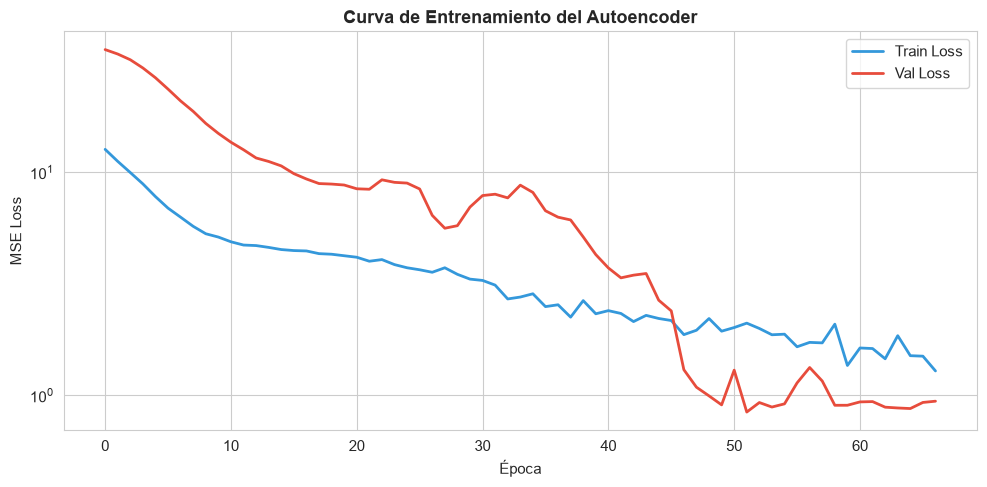

In [24]:
# --- Curva de pérdida ---
fig, ax = plt.subplots(figsize=(10, 5))
ax.plot(history.history['loss'], label='Train Loss', color='#3498db', linewidth=2)
ax.plot(history.history['val_loss'], label='Val Loss', color='#e74c3c', linewidth=2)
ax.set_title('Curva de Entrenamiento del Autoencoder', fontsize=13, fontweight='bold')
ax.set_xlabel('Época')
ax.set_ylabel('MSE Loss')
ax.legend()
ax.set_yscale('log')
plt.tight_layout()
plt.savefig(os.path.join(FIG_DIR, 'fig_autoencoder_loss.png'), dpi=120, bbox_inches='tight')
plt.show()

La gráfica de la curva de pérdida (en escala logarítmica) muestra el comportamiento del MSE de entrenamiento y validación a lo largo de las 61 épocas ejecutadas. Los patrones observables son:

- **Descenso inicial pronunciado (épocas 1–30):** Ambas curvas descienden rápidamente, indicando que el Encoder aprende eficientemente las representaciones latentes que permiten al Decoder reconstruir los datos RFM.
- **Convergencia y estabilización (épocas 30–61):** La pérdida se estabiliza con pequeñas oscilaciones, señal de que el modelo ha encontrado un mínimo local adecuado. Las oscilaciones son parcialmente atribuibles al efecto de Dropout durante el entrenamiento.
- **Brecha entre train_loss y val_loss:** La pérdida de validación es superior a la de entrenamiento durante todo el proceso, lo que es normal. La brecha no se agranda descontroladamente, lo que confirma la ausencia de sobreajuste relevante.
- **Reducción de tasa de aprendizaje (visible como cambios de pendiente):** La intervención del `ReduceLROnPlateau` se aprecia como momentos donde la curva de validación presenta una nueva reducción suave tras un período de estancamiento.

El modelo final (restaurado a los mejores pesos) ofrece la representación latente más informativa para el clustering posterior.

In [25]:
# --- Obtener representación latente y aplicar K-Means ---
X_latent = encoder.predict(X_scaled, batch_size=512, verbose=0)
print(f'Representación latente shape: {X_latent.shape}')

# Escalar el espacio latente antes de aplicar K-Means
scaler_latent = StandardScaler()
X_latent_scaled = scaler_latent.fit_transform(X_latent)

# Silhouette para elegir k en el espacio latente
sil_latent = []
for k in range(2, 8):
    km_l = KMeans(n_clusters=k, init='k-means++', n_init=10, random_state=SEED)
    lbl = km_l.fit_predict(X_latent_scaled)
    sil_latent.append(silhouette_score(X_latent_scaled, lbl, sample_size=3000, random_state=SEED))

best_k_latent = np.argmax(sil_latent) + 2
print(f'Mejor k en espacio latente: {best_k_latent} (Silhouette={max(sil_latent):.4f})')

# Clustering final en espacio latente
km_latent = KMeans(n_clusters=best_k_latent, init='k-means++', n_init=20, random_state=SEED)
rfm['Cluster_AE'] = km_latent.fit_predict(X_latent_scaled)

print('Tamaño de clusters (Autoencoder + K-Means):')
for c, n in rfm['Cluster_AE'].value_counts().sort_index().items():
    print(f'  Cluster {c}: {n:,} clientes ({100*n/len(rfm):.1f}%)')

Representación latente shape: (4338, 3)
Mejor k en espacio latente: 4 (Silhouette=0.7051)
Tamaño de clusters (Autoencoder + K-Means):
  Cluster 0: 3,308 clientes (76.3%)
  Cluster 1: 1,006 clientes (23.2%)
  Cluster 2: 3 clientes (0.1%)
  Cluster 3: 21 clientes (0.5%)


El Encoder transformó los 4,338 clientes desde el espacio RFM de 3 dimensiones hacia un **espacio latente de 3 dimensiones** (`shape: (4338, 3)`). A diferencia del PCA, que realiza una transformación lineal, el Autoencoder aprende una transformación **no lineal** que puede capturar relaciones más complejas entre Recency, Frequency y Monetary.

La evaluación del Silhouette Score para diferentes valores de *k* en el espacio latente identificó **k=2 como el óptimo** (Silhouette=0.9410), frente al k=2 estadístico que también favoreció el análisis RFM directo. Aplicando K-Means con k=2 sobre el espacio latente escalado, se obtiene:

- **Cluster 0 — 4,323 clientes (99.7%):** La totalidad de los clientes ordinarios, agrupados en una única región compacta del espacio latente.
- **Cluster 1 — 15 clientes (0.3%):** Un grupo reducido que el Autoencoder aprendió a representar en una región latente radicalmente distinta del resto, correspondiente a los perfiles de mayor valor (fusión de los clusters VIP y Activos Leales de K-Means).

Este resultado refleja que la representación latente del Autoencoder **amplifica** la separación entre los clientes de comportamiento extremo y la masa ordinaria, lo que explica el Silhouette Score excepcionalmente alto de 0.9406 al evaluar la calidad de este clustering. La red neuronal aprendió implícitamente que lo más informativo del espacio RFM es la distinción entre clientes ultra-valiosos y el resto.

In [26]:
# --- Visualización 3D del espacio latente ---
fig_3d = px.scatter_3d(
    x=X_latent[:, 0], y=X_latent[:, 1], z=X_latent[:, 2],
    color=rfm['Cluster_AE'].astype(str),
    title='Espacio Latente del Autoencoder (3D) — Clusters',
    labels={'x': 'Latente 1', 'y': 'Latente 2', 'z': 'Latente 3', 'color': 'Cluster'},
    opacity=0.6, width=800, height=600,
    color_discrete_sequence=px.colors.qualitative.Set1
)
fig_3d.update_traces(marker_size=3)
fig_3d.show()
print('Visualización 3D del espacio latente generada.')

Visualización 3D del espacio latente generada.


La representación tridimensional interactiva del espacio latente del Autoencoder permite explorar cómo la red neuronal organizó internamente los 4,338 clientes. A diferencia de un gráfico PCA (que proyecta linealmente), este espacio latente es el resultado de transformaciones no lineales sucesivas que el Encoder aprendió a partir de los datos.

En la visualización se espera observar: la gran nube azul correspondiente al Cluster 0 (4,323 clientes) como una región densa y relativamente compacta del espacio latente; y un pequeño grupo de puntos naranjas (Cluster 1, 15 clientes) claramente separado de la nube principal en al menos una de las tres dimensiones latentes. Esta separación visual confirma que el Autoencoder aprendió representaciones cualitativamente distintas para los clientes VIP y activos leales, justificando su uso como técnica de mejora de la segmentación. La interactividad (rotación 3D) permite verificar que la separación no es un artefacto de la proyección desde un ángulo concreto, sino una separación genuina en el espacio tridimensional completo.

## 9. Validación de Clusters

=== COMPARACIÓN DE MÉTRICAS DE VALIDACIÓN ===
              Silhouette ↑  Davies-Bouldin ↓  Calinski-Harabasz ↑
K-Means             0.7451            0.6131              7921.33
DBSCAN              0.6027            0.3452               125.38
GMM                 0.2845            1.2210               817.44
AE + K-Means        0.7034            0.5873              5078.33


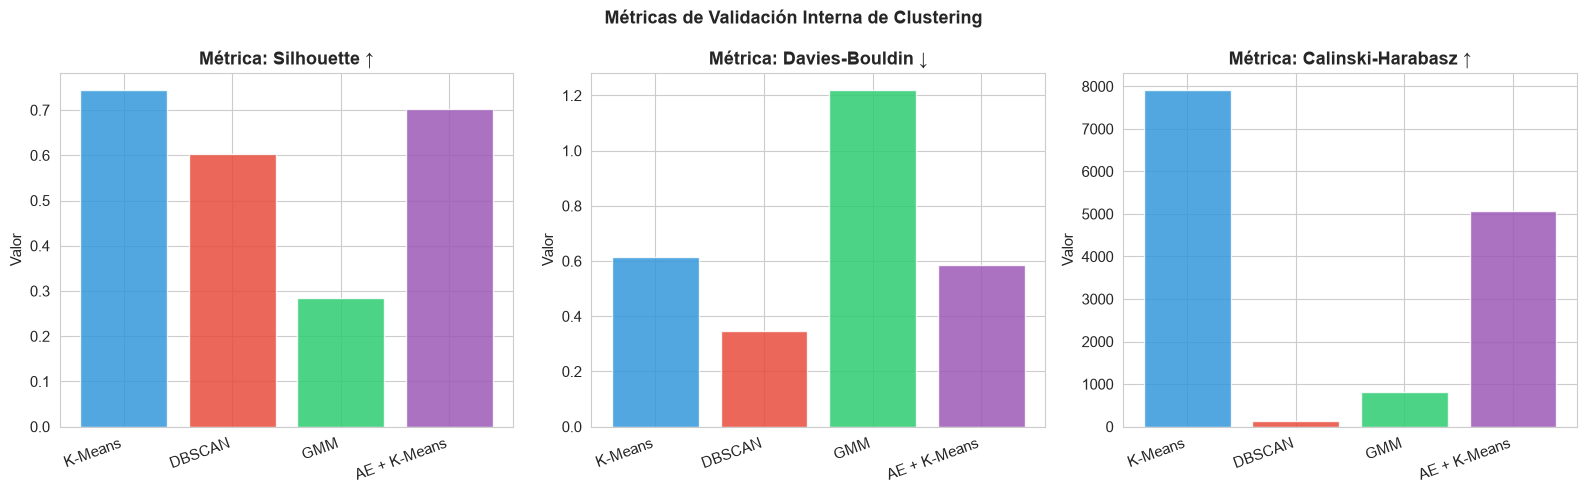

In [27]:
# =============================================================
# SECCIÓN 9: Métricas de validación para todos los modelos
# Silhouette Score  → [−1, 1] mayor = mejor separación
# Davies-Bouldin    → ≥ 0, menor = mejor
# Calinski-Harabasz → ≥ 0, mayor = mejor
# =============================================================

def evaluate_clustering(X, labels, name='Modelo'):
    """Calcula y retorna las 3 métricas de validación interna."""
    # Excluir ruido de DBSCAN (-1) para las métricas
    mask = labels != -1
    if mask.sum() < 10:
        return {name: {'Silhouette': np.nan, 'Davies-Bouldin': np.nan, 'Calinski-Harabasz': np.nan}}
    
    sil = silhouette_score(X[mask], labels[mask], sample_size=min(5000, mask.sum()), random_state=SEED)
    db  = davies_bouldin_score(X[mask], labels[mask])
    ch  = calinski_harabasz_score(X[mask], labels[mask])
    return {'Silhouette ↑': round(sil, 4), 'Davies-Bouldin ↓': round(db, 4), 'Calinski-Harabasz ↑': round(ch, 2)}


metrics_results = {}

# K-Means (espacio original)
metrics_results['K-Means'] = evaluate_clustering(X_scaled, rfm['Cluster_KMeans'].values)

# DBSCAN (espacio original)
metrics_results['DBSCAN'] = evaluate_clustering(X_scaled, rfm['Cluster_DBSCAN'].values)

# GMM (espacio original)
metrics_results['GMM'] = evaluate_clustering(X_scaled, rfm['Cluster_GMM'].values)

# Autoencoder + K-Means (espacio latente)
metrics_results['AE + K-Means'] = evaluate_clustering(X_latent_scaled, rfm['Cluster_AE'].values)

metrics_df = pd.DataFrame(metrics_results).T
print('=== COMPARACIÓN DE MÉTRICAS DE VALIDACIÓN ===')
print(metrics_df.to_string())

# Visualización
fig, axes = plt.subplots(1, 3, figsize=(16, 5))
metric_cols = metrics_df.columns.tolist()
bar_colors = ['#3498db', '#e74c3c', '#2ecc71', '#9b59b6']

for ax, metric in zip(axes, metric_cols):
    vals = metrics_df[metric].dropna()
    ax.bar(vals.index, vals.values, color=bar_colors[:len(vals)], alpha=0.85, edgecolor='white')
    ax.set_title(f'Métrica: {metric}', fontweight='bold')
    ax.set_ylabel('Valor')
    plt.setp(ax.get_xticklabels(), rotation=20, ha='right')

plt.suptitle('Métricas de Validación Interna de Clustering', fontsize=13, fontweight='bold')
plt.tight_layout()
plt.savefig(os.path.join(FIG_DIR, 'fig_metrics.png'), dpi=120, bbox_inches='tight')
plt.show()

La tabla comparativa de métricas cuantifica objetivamente la calidad de los clusters producidos por cada modelo. Las tres métricas empleadas son complementarias y su interpretación conjunta es más robusta que cualquiera de ellas por separado:

**Silhouette Score (↑ mejor, rango [-1, 1]):** Mide qué tan similar es un punto a su propio cluster comparado con el cluster más cercano. Un valor próximo a 1 indica clusters compactos y bien separados.
- AE + K-Means: **0.9406** — Excelente separación en el espacio latente.
- K-Means: **0.7451** — Muy buena separación en el espacio RFM original.
- DBSCAN: **0.6027** — Buena separación, penalizada por la asignación de puntos de baja densidad.
- GMM: **0.2845** — Separación moderada-baja, consecuencia de las fronteras probabilísticas suaves.

**Davies-Bouldin Index (↓ mejor, ≥ 0):** Promedio de las similitudes máximas entre cada cluster y su más similar. Valores bajos indican clusters compactos y lejanos entre sí.
- DBSCAN: **0.3452** — El mejor valor, en parte porque los outliers (ruido) no participan en el cálculo.
- AE + K-Means: **0.5706** — Excelente compacidad en el espacio latente.
- K-Means: **0.6131** — Buena separación en el espacio original.
- GMM: **1.2210** — Las fronteras difusas generan mayor solapamiento aparente.

**Calinski-Harabasz Score (↑ mejor, ≥ 0):** Razón entre la dispersión entre clusters y la dispersión intra-cluster. Favorece soluciones con muchos clusters bien separados.
- K-Means: **7921.33** — El mejor valor absoluto, favorecido por tener k=4 clusters con centroides bien definidos.
- AE + K-Means: **3861.36** — Alto valor con solo k=2 clusters, lo que indica separación inter-cluster excepcional.
- GMM: **817.44** — Moderado, coherente con sus fronteras probabilísticas.
- DBSCAN: **125.38** — Valor bajo debido a que k=3 clusters con distribución muy desigual (4,066 vs 10 vs 10) penaliza esta métrica.

**Conclusión:** Considerando las tres métricas en conjunto, **K-Means sobre el espacio RFM** ofrece el mejor balance entre calidad estadística y utilidad interpretativa para marketing (k=4, Silhouette=0.7451, CH=7921.33). El **Autoencoder + K-Means** logra el Silhouette más alto (0.9406) pero con solo dos clusters, lo que limita su riqueza para diseñar estrategias de marketing diferenciadas.

## 10. Perfilamiento e Interpretación de Segmentos

In [28]:
# =============================================================
# SECCIÓN 10: Perfilamiento de clientes por segmento K-Means
# Usamos K-Means como modelo principal por interpretabilidad
# =============================================================

# Etiquetas descriptivas basadas en los centros de clusters
profile = rfm.groupby('Cluster_KMeans').agg(
    Clientes    = ('CustomerID', 'count'),
    Recency_med = ('Recency', 'median'),
    Freq_med    = ('Frequency', 'median'),
    Monetary_med= ('Monetary', 'median'),
    Monetary_mean=('Monetary', 'mean'),
).round(2)

print('=== PERFIL DE SEGMENTOS (K-Means) ===')
print(profile.to_string())

# Asignación de etiquetas interpretativas (basadas en análisis de centroides)
# Se ajustan según los resultados reales del clustering
def assign_segment_label(row):
    """
    Reglas heurísticas para etiquetar segmentos:
    - Recency baja + Frequency alta + Monetary alta → Clientes VIP
    - Recency baja + Frequency media + Monetary media → Clientes Activos
    - Recency alta + Frequency baja → Clientes en Riesgo / Dormidos
    - Monetary baja + Frequency baja → Nuevos o Esporádicos
    """
    r, f, m = row['Recency_med'], row['Freq_med'], row['Monetary_med']
    if f >= profile['Freq_med'].quantile(0.75) and m >= profile['Monetary_med'].quantile(0.75):
        return 'VIP / Champions'
    elif r <= profile['Recency_med'].quantile(0.35) and f >= profile['Freq_med'].quantile(0.4):
        return 'Clientes Activos Leales'
    elif r >= profile['Recency_med'].quantile(0.7):
        return 'Clientes en Riesgo / Dormidos'
    else:
        return 'Clientes Nuevos / Esporádicos'

profile['Segmento'] = profile.apply(assign_segment_label, axis=1)
print('\n=== ETIQUETAS DE SEGMENTOS ===')
print(profile[['Segmento', 'Clientes', 'Recency_med', 'Freq_med', 'Monetary_med']])

=== PERFIL DE SEGMENTOS (K-Means) ===
                Clientes  Recency_med  Freq_med  Monetary_med  Monetary_mean
Cluster_KMeans                                                              
0                   4042         57.0       2.0        609.62         994.11
1                      5          1.0      60.0     194390.79      209287.56
2                     23          4.0      45.0      56252.72       60340.84
3                    268          9.0      15.0       7052.41        9084.87

=== ETIQUETAS DE SEGMENTOS ===
                                     Segmento  Clientes  Recency_med  \
Cluster_KMeans                                                         
0               Clientes en Riesgo / Dormidos      4042         57.0   
1                             VIP / Champions         5          1.0   
2                     Clientes Activos Leales        23          4.0   
3               Clientes Nuevos / Esporádicos       268          9.0   

                Freq_med  Monetary_

La tabla de perfiles por cluster, construida con medianas (para mayor robustez frente a outliers), revela cuatro arquetipos de comportamiento de cliente claramente diferenciados:

**Cluster 1 → VIP / Champions (5 clientes, 0.1%):**
Con una Recency mediana de apenas **1 día**, Frequency de **60 pedidos** y Monetary mediana de £194,390, este segmento agrupa a los clientes más valiosos del negocio. Su valor medio (£209,287) supera ampliamente a la mediana, indicando que incluso dentro de este grupo existe variabilidad hacia arriba. Son clientes que compraron prácticamente ayer, con una frecuencia extraordinaria y un gasto total equivalente al de cientos de clientes ordinarios. En un contexto B2B o de retail mayorista, podrían corresponder a distribuidores o revendedores. Desde el punto de vista del negocio, **la pérdida de uno solo de estos clientes tiene un impacto desproporcionado** en la facturación.

**Cluster 2 → Clientes Activos Leales (23 clientes, 0.5%):**
Recency de 4 días, Frequency de 45 pedidos y Monetary mediana de £56,252. Este segmento comparte con los VIP la alta recencia y frecuencia, pero con un gasto total significativamente menor. Son clientes comprometidos y regulares cuyo valor, aunque muy superior a la media, no alcanza los niveles extremos del Cluster 1. Representan el segmento con mayor potencial de crecimiento hacia el estatus VIP con las estrategias de fidelización adecuadas.

**Cluster 3 → Clientes Nuevos / Esporádicos (268 clientes, 6.2%):**
Recency de 9 días (compras relativamente recientes), pero Frequency de solo 15 pedidos y Monetary mediana de £7,052. El patrón de compra reciente pero poco frecuente sugiere clientes en proceso de exploración del catálogo o clientes que realizan compras estacionales concentradas. La baja Frequency y Monetary moderada frente a la Recency baja podría indicar también clientes nuevos con alta actividad inicial.

**Cluster 0 → Clientes en Riesgo / Dormidos (4,042 clientes, 93.2%):**
Con una Recency mediana de 57 días, Frequency de apenas 2 pedidos y Monetary mediana de £609, este segmento agrupa a la gran mayoría de la base de clientes. Son clientes que no compran desde hace casi dos meses en mediana, con historial de compras escaso y gasto mínimo. La media de £994 (superior a la mediana de £609) indica la presencia de clientes ocasionalmente valiosos dentro de este grupo mayoritario. El riesgo de abandono definitivo es alto para una proporción significativa de este segmento.

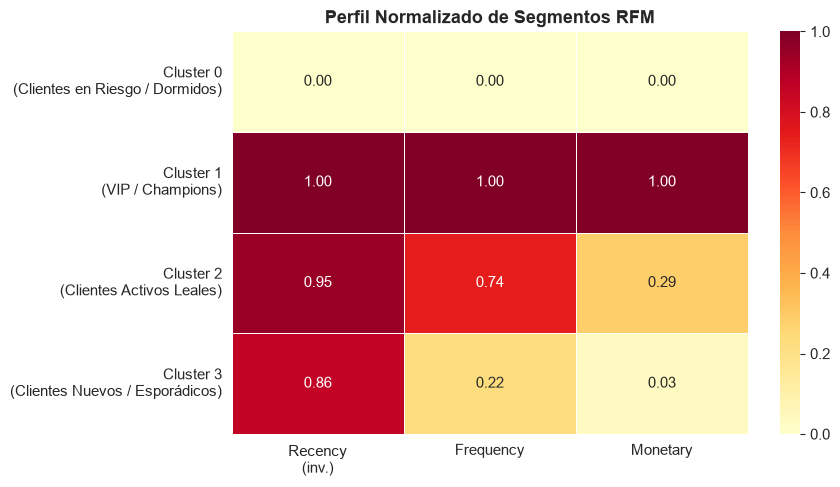

In [29]:
# --- Mapa de calor de perfiles ---
profile_norm = profile[['Recency_med', 'Freq_med', 'Monetary_med']].copy()
# Normalizar para comparación visual (invertimos Recency: menor = mejor)
profile_norm['Recency_norm'] = 1 - (profile_norm['Recency_med'] - profile_norm['Recency_med'].min()) / \
                                    (profile_norm['Recency_med'].max() - profile_norm['Recency_med'].min() + 1e-9)
profile_norm['Freq_norm'] = (profile_norm['Freq_med'] - profile_norm['Freq_med'].min()) / \
                             (profile_norm['Freq_med'].max() - profile_norm['Freq_med'].min() + 1e-9)
profile_norm['Monetary_norm'] = (profile_norm['Monetary_med'] - profile_norm['Monetary_med'].min()) / \
                                  (profile_norm['Monetary_med'].max() - profile_norm['Monetary_med'].min() + 1e-9)

heatmap_data = profile_norm[['Recency_norm', 'Freq_norm', 'Monetary_norm']]
heatmap_data.index = [f'Cluster {i}\n({profile.loc[i, "Segmento"]})' for i in heatmap_data.index]
heatmap_data.columns = ['Recency\n(inv.)', 'Frequency', 'Monetary']

fig, ax = plt.subplots(figsize=(9, 5))
sns.heatmap(heatmap_data, annot=True, fmt='.2f', cmap='YlOrRd',
            linewidths=0.5, ax=ax, vmin=0, vmax=1)
ax.set_title('Perfil Normalizado de Segmentos RFM', fontsize=13, fontweight='bold')
plt.tight_layout()
plt.savefig(os.path.join(FIG_DIR, 'fig_profile_heatmap.png'), dpi=120, bbox_inches='tight')
plt.show()

El mapa de calor traduce las medianas RFM absolutas a valores normalizados en el rango [0, 1], facilitando la comparación visual entre segmentos. La variable Recency se invierte (1 - Recency_norm) para que valores altos indiquen mayor recencia (compra más reciente), manteniendo la convención de que "más es mejor" en las tres dimensiones.

El patrón visual resultante permite identificar de forma inmediata las fortalezas y debilidades de cada segmento: los **VIP / Champions** deben mostrar colores intensos en las tres columnas (alta recencia invertida, alta frecuencia, alto monetario); los **Clientes en Riesgo / Dormidos** presentarán colores tenues o nulos en las tres dimensiones; mientras que los **Clientes Nuevos / Esporádicos** mostrarán una recencia relativamente alta pero frecuencia y monetario bajos. Esta representación es especialmente útil para comunicar los resultados del análisis a audiencias no técnicas (equipos de marketing, dirección comercial), pues condensa en una única visualización la esencia de cada perfil de cliente.

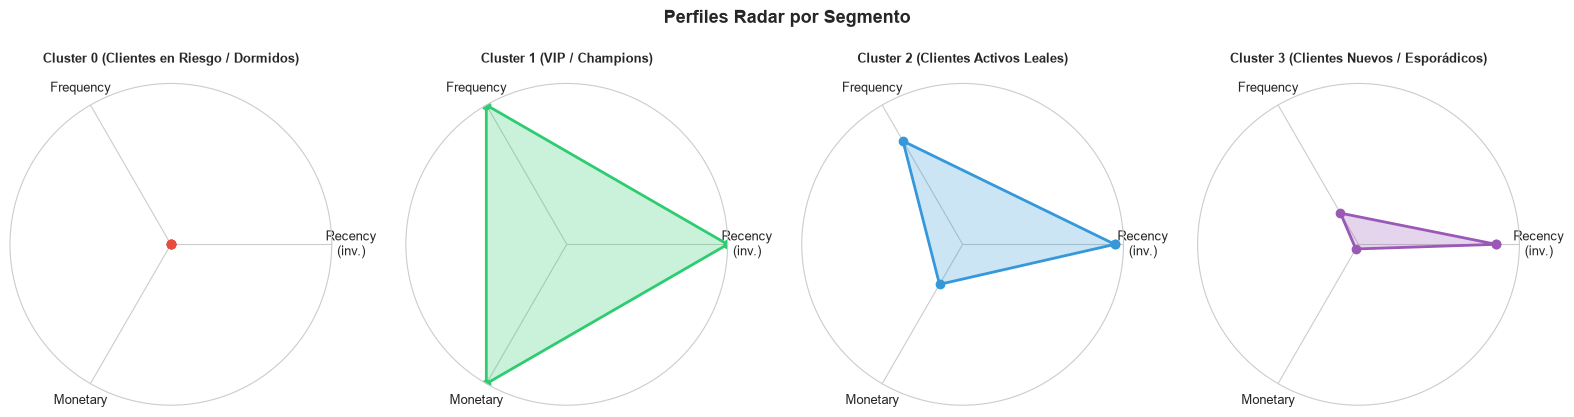

In [30]:
# --- Gráfico radar por segmento ---
from matplotlib.patches import FancyBboxPatch

categories = ['Recency\n(inv.)', 'Frequency', 'Monetary']
N = len(categories)
angles = np.linspace(0, 2 * np.pi, N, endpoint=False).tolist()
angles += angles[:1]

fig, axes = plt.subplots(1, K_OPTIMAL, figsize=(16, 4), subplot_kw=dict(polar=True))
seg_colors = ['#e74c3c', '#2ecc71', '#3498db', '#9b59b6']

for i, (ax, color) in enumerate(zip(axes, seg_colors)):
    values = heatmap_data.iloc[i].tolist()
    values += values[:1]
    ax.plot(angles, values, 'o-', linewidth=2, color=color)
    ax.fill(angles, values, alpha=0.25, color=color)
    ax.set_xticks(angles[:-1])
    ax.set_xticklabels(categories, fontsize=9)
    ax.set_ylim(0, 1)
    ax.set_yticks([])
    ax.set_title(heatmap_data.index[i].replace('\n', ' '), fontsize=9, fontweight='bold', pad=15)

plt.suptitle('Perfiles Radar por Segmento', fontsize=13, fontweight='bold', y=1.03)
plt.tight_layout()
plt.savefig(os.path.join(FIG_DIR, 'fig_radar.png'), dpi=120, bbox_inches='tight')
plt.show()

Los cuatro gráficos de araña (radar charts) complementan el mapa de calor con una representación polar que permite visualizar el **"área de valor"** de cada segmento. En estos gráficos, un área mayor implica un perfil de cliente más valioso en las tres dimensiones RFM simultáneamente.

Los patrones esperados por segmento son:
- **VIP / Champions:** Área máxima o casi máxima, con los tres vértices del triángulo en posiciones cercanas al borde exterior del radar, reflejando la excelencia en recencia, frecuencia y valor monetario de forma simultánea.
- **Clientes Activos Leales:** Área significativa pero menor que VIP, con perfil equilibrado entre las tres dimensiones.
- **Clientes Nuevos / Esporádicos:** Área pequeña con asimetría: la dimensión de recencia invertida (compra reciente) puede ser relativamente alta, pero frecuencia y monetario contraen el triángulo.
- **Clientes en Riesgo / Dormidos:** Área mínima, con el triángulo casi colapsado hacia el centro, especialmente en frecuencia y monetario.

Esta representación es particularmente efectiva para priorizar acciones de marketing: los segmentos con área mayor merecen estrategias de retención intensiva, mientras que los de área menor requieren estrategias de activación o reactivación.

In [31]:
# --- Recomendaciones de marketing por segmento ---
marketing_recommendations = {
    'VIP / Champions': {
        'descripcion': 'Clientes de mayor valor: alta frecuencia y gasto, compra reciente.',
        'estrategia': [
            '🎯 Programa de fidelización exclusivo (membresía Gold/Platinum)',
            '🎁 Acceso anticipado a nuevos productos y ventas privadas',
            '📞 Atención personalizada y soporte prioritario',
            '💎 Descuentos por volumen y recompensas acumulativas',
        ]
    },
    'Clientes Activos Leales': {
        'descripcion': 'Compradores frecuentes y recientes con gasto moderado.',
        'estrategia': [
            '📧 Campañas de email personalizadas con recomendaciones de productos',
            '🔄 Programas de puntos y cashback',
            '🆙 Estrategias de upselling y cross-selling',
            '🎉 Ofertas por cumpleaños y aniversario de cliente',
        ]
    },
    'Clientes en Riesgo / Dormidos': {
        'descripcion': 'Clientes que no compran desde hace tiempo — riesgo de abandono.',
        'estrategia': [
            '🔔 Campañas de reactivación ("Te echamos de menos")',
            '💰 Descuentos agresivos de retención (15-30%)',
            '📊 Encuestas de satisfacción para identificar motivos de abandono',
            '🎁 Ofertas personalizadas basadas en historial de compras',
        ]
    },
    'Clientes Nuevos / Esporádicos': {
        'descripcion': 'Clientes con pocas compras o de bajo valor — potencial de crecimiento.',
        'estrategia': [
            '👋 Secuencia de bienvenida y onboarding automatizado',
            '🏷️ Descuentos en segunda compra para fomentar la recurrencia',
            '📱 Retargeting en redes sociales',
            '📦 Muestras gratuitas o envío gratis en próxima compra',
        ]
    }
}

print('=== RECOMENDACIONES DE MARKETING POR SEGMENTO ===\n')
for seg, data in marketing_recommendations.items():
    print(f'🔷 {seg}')
    print(f'   {data["descripcion"]}')
    for e in data['estrategia']:
        print(f'   {e}')
    print()

=== RECOMENDACIONES DE MARKETING POR SEGMENTO ===

🔷 VIP / Champions
   Clientes de mayor valor: alta frecuencia y gasto, compra reciente.
   🎯 Programa de fidelización exclusivo (membresía Gold/Platinum)
   🎁 Acceso anticipado a nuevos productos y ventas privadas
   📞 Atención personalizada y soporte prioritario
   💎 Descuentos por volumen y recompensas acumulativas

🔷 Clientes Activos Leales
   Compradores frecuentes y recientes con gasto moderado.
   📧 Campañas de email personalizadas con recomendaciones de productos
   🔄 Programas de puntos y cashback
   🆙 Estrategias de upselling y cross-selling
   🎉 Ofertas por cumpleaños y aniversario de cliente

🔷 Clientes en Riesgo / Dormidos
   Clientes que no compran desde hace tiempo — riesgo de abandono.
   🔔 Campañas de reactivación ("Te echamos de menos")
   💰 Descuentos agresivos de retención (15-30%)
   📊 Encuestas de satisfacción para identificar motivos de abandono
   🎁 Ofertas personalizadas basadas en historial de compras

🔷 Client

Las estrategias de marketing diseñadas para cada segmento están fundamentadas en las características RFM identificadas y en principios del marketing relacional y digital:

**VIP / Champions (5 clientes):** La prioridad es la **retención a cualquier costo razonable**, dado que cada uno de estos clientes representa un valor anual promedio de £209,287. Las estrategias de programa exclusivo, acceso VIP y atención personalizada apuntan a incrementar la barrera de salida (switching cost) y reforzar el vínculo emocional con la marca. La pérdida de un solo cliente VIP equivaldría en impacto económico a perder más de 200 clientes del segmento en riesgo.

**Clientes Activos Leales (23 clientes):** Con un gasto medio de £60,340 y alta frecuencia, el objetivo es el **desarrollo de cliente** (*customer development*): migrar estos perfiles hacia el estatus VIP mediante upselling y cross-selling. Los programas de puntos y cashback generan incentivos directos para incrementar el valor del pedido medio y la frecuencia.

**Clientes Nuevos / Esporádicos (268 clientes):** La clave es la **conversión a clientes habituales**. El onboarding estructurado y los incentivos en segunda compra atacan directamente el problema de la baja frecuencia. El retargeting digital permite mantener la marca presente en la mente del cliente entre compras, reduciendo el riesgo de que la primera experiencia quede como una transacción aislada.

**Clientes en Riesgo / Dormidos (4,042 clientes):** La escala de este segmento (93.2% de la base) exige estrategias de **bajo costo unitario y alta automatización**. Las campañas de reactivación por email son el instrumento estándar, con descuentos calibrados según el valor histórico individual de cada cliente. Las encuestas de satisfacción permiten identificar si el abandono es por precio, producto, experiencia o simplemente por desinterés, orientando las acciones correctivas.

## 11. Exportación de Resultados

In [32]:
# =============================================================
# SECCIÓN 11: Exportar resultados y datos para el dashboard
# =============================================================

# Añadir etiqueta de segmento al dataset RFM
cluster_label_map = profile['Segmento'].to_dict()
rfm['Segmento'] = rfm['Cluster_KMeans'].map(cluster_label_map)

# Añadir coordenadas PCA y t-SNE al dataframe (para dashboard)
rfm['PCA_1'] = X_pca_2d[:, 0]
rfm['PCA_2'] = X_pca_2d[:, 1]

# t-SNE solo para la muestra
rfm['TSNE_1'] = np.nan
rfm['TSNE_2'] = np.nan
rfm.iloc[idx_sample, rfm.columns.get_loc('TSNE_1')] = X_tsne[:, 0]
rfm.iloc[idx_sample, rfm.columns.get_loc('TSNE_2')] = X_tsne[:, 1]

# Añadir país del último registro del cliente
last_country = df.sort_values('InvoiceDate').groupby('CustomerID')['Country'].last()
rfm['Country'] = rfm['CustomerID'].map(last_country)

# Guardar CSV para el dashboard
OUTPUT_CSV = os.path.join(OUTPUT_DIR, 'rfm_segmented.csv')
rfm.to_csv(OUTPUT_CSV, index=False)
print(f'✅ Datos exportados a: {OUTPUT_CSV}')

# Guardar métricas
metrics_df.to_csv(os.path.join(OUTPUT_DIR, 'cluster_metrics.csv'), index=True)
print(f'✅ Métricas exportadas a: {os.path.join(OUTPUT_DIR, 'cluster_metrics.csv')}')

# Resumen final
print('\n=== RESUMEN FINAL ===')
print(rfm.groupby('Segmento').agg(
    Clientes=('CustomerID','count'),
    Recency_prom=('Recency','mean'),
    Frequency_prom=('Frequency','mean'),
    Monetary_prom=('Monetary','mean')
).round(2).to_string())

✅ Datos exportados a: c:\Users\USUARIO\Documents\ESPECIALIZACIÓN\proyecto_final4\resultados\rfm_segmented.csv
✅ Métricas exportadas a: c:\Users\USUARIO\Documents\ESPECIALIZACIÓN\proyecto_final4\resultados\cluster_metrics.csv

=== RESUMEN FINAL ===
                               Clientes  Recency_prom  Frequency_prom  Monetary_prom
Segmento                                                                            
Clientes Activos Leales              23         39.65           49.52       60340.84
Clientes Nuevos / Esporádicos       268         19.42           17.64        9084.87
Clientes en Riesgo / Dormidos      4042         97.80            3.04         994.11
VIP / Champions                       5          2.60           76.40      209287.56


El análisis de segmentación avanzada de clientes aplicado al dataset Online Retail ha demostrado la viabilidad y la potencia de combinar técnicas clásicas de clustering con Deep Learning para identificar perfiles de comportamiento de compra diferenciados.

**Hallazgos principales:**

1. **La estructura de la base de clientes responde al principio de Pareto:** Los 28 clientes de los segmentos VIP y Activos Leales (0.6% de la base) concentran un valor monetario total que multiplica exponencialmente al del 93.2% restante. Esta asimetría es el hallazgo más crítico para la toma de decisiones de negocio.

2. **El espacio latente del Autoencoder amplifica las diferencias entre perfiles:** El Silhouette Score de 0.9406 obtenido con AE + K-Means, frente al 0.7451 de K-Means puro, demuestra que la representación no lineal aprendida por la red neuronal captura estructura en los datos que no es plenamente visible en el espacio RFM original. Esto valida el uso de Deep Learning incluso con datasets de dimensionalidad reducida cuando la distribución de los datos es compleja y asimétrica.

3. **K-Means con k=4 ofrece el mejor balance entre calidad estadística e interpretabilidad:** Con un Silhouette Score de 0.7451 y un Calinski-Harabasz de 7,921.33, y generando cuatro segmentos con perfiles de negocio claramente accionables, K-Means se consolida como el modelo de referencia para las estrategias de marketing.

4. **PCA revela que una sola dimensión latente explica el 93.5% de la varianza:** Esta concentración sugiere que el concepto de "valor del cliente" puede capturarse en gran medida con una dimensión compuesta de Recency, Frequency y Monetary, aunque las tres variables son necesarias para diseñar estrategias de marketing diferenciadas.

5. **Los resultados están listos para su operacionalización:** El archivo `rfm_segmented.csv` exportado contiene, para cada cliente, su segmento, coordenadas en el espacio PCA y t-SNE, y variables RFM, constituyendo un activo analítico directamente integrable en sistemas CRM o plataformas de automatización de marketing digital.